# Transformer sentiment classification on IMDB

## 1. Experiment configuration

Defines the candidate models, screening settings, training controls, and final evaluation switches used by the notebook.


In [1]:
# Required experiment switches
USE_GOOGLE_DRIVE = True
RUN_HPO = True
HPO_TRIALS = 2
RUN_FINAL_MULTI_SEED = True
USE_LLRD = False
RUN_THRESHOLD_SEARCH = True
RUN_ENSEMBLE_SELECTION = False
ALLOW_FINAL_TEST_EVALUATION = True

MODEL_CANDIDATES = [
    "microsoft/deberta-v3-base",
    "microsoft/deberta-v3-small",
    "FacebookAI/roberta-base",
    "distilroberta-base",
    "google/electra-base-discriminator",
]
MODEL_NAME = None

TOKENIZER_USE_FAST = False
MAX_LENGTH = 384
FINAL_SEEDS = [42]
USE_GRADIENT_CHECKPOINTING = False

# Model-screening controls
RUN_MODEL_SCREENING = True
SCREEN_TRAIN_EXAMPLES = 1_500
SCREEN_VALIDATION_EXAMPLES = 500
SCREEN_MAX_LENGTH = 192
SCREEN_EPOCHS = 1
SCREEN_TRAIN_BATCH_SIZE = 8
SCREEN_GRADIENT_ACCUMULATION = 2

# Development controls
RUN_SMOKE_TEST = True
RUN_TRUNCATION_COMPARISON = False
RUN_FOCUSED_CONFIRMATION = False
RUN_TTA_VALIDATION = False
HPO_TRAIN_EXAMPLES = 4_000
FOCUSED_TOP_K = 1
CONFIRMATION_SEEDS = [42]
INITIAL_MICRO_BATCH_SIZE = 4
EARLY_STOPPING_PATIENCE = 1
DEVELOPMENT_RANDOM_STATE = 42
FIXED_TRUNCATION_STRATEGY = "head_tail"

# Storage controls
USE_LOCAL_TRAINING_CHECKPOINTS = True
DELETE_LOCAL_CHECKPOINTS_AFTER_STAGE = True
RETAIN_INTERMEDIATE_MODELS = False

assert len(MODEL_CANDIDATES) == 5
assert len(set(MODEL_CANDIDATES)) == 5
assert SCREEN_TRAIN_EXAMPLES > 0
assert SCREEN_VALIDATION_EXAMPLES > 0
assert SCREEN_MAX_LENGTH <= MAX_LENGTH
assert FINAL_SEEDS == [42]
assert ALLOW_FINAL_TEST_EVALUATION is True


## 2. Colab T4 setup

Checks the GPU runtime and prints the system information used by training.


In [2]:
import json
import os
import platform
import subprocess
import sys

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_IMPLICIT_TOKEN"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["USE_TF"] = "0"
os.environ["TRANSFORMERS_NO_TF"] = "1"


def query_gpu() -> dict:
    command = [
        "nvidia-smi",
        "--query-gpu=name,memory.total,driver_version",
        "--format=csv,noheader,nounits",
    ]
    try:
        row = subprocess.check_output(
            command, text=True, stderr=subprocess.STDOUT
        ).strip().splitlines()[0]
    except Exception as error:
        raise RuntimeError(
            "No NVIDIA GPU runtime is available. In Colab choose "
            "Runtime > Change runtime type > T4 GPU, then reconnect."
        ) from error
    name, memory_mb, driver = [part.strip() for part in row.split(",")]
    return {
        "name": name,
        "memory_mb": int(memory_mb),
        "driver": driver,
    }


GPU_INFO = query_gpu()
print("GPU:", GPU_INFO["name"])
print("GPU memory (MiB):", GPU_INFO["memory_mb"])
print("NVIDIA driver:", GPU_INFO["driver"])
print("Python:", sys.version.split()[0])
if "T4" not in GPU_INFO["name"].upper():
    print("Warning: settings are validated for a T4; detected", GPU_INFO["name"])


GPU: Tesla T4
GPU memory (MiB): 15360
NVIDIA driver: 580.82.07
Python: 3.12.13


## 3. Dependency installation

Installs missing dependencies and confirms the five candidate model names.


In [3]:
from pathlib import Path
import importlib.metadata
import importlib.util
import re

REQUIREMENTS_FILE = Path.cwd() / "requirements_colab_transformer.txt"
FALLBACK_REQUIREMENTS = [
    "torch>=2.4.0,<3.0",
    "transformers==4.57.3",
    "datasets>=3.2.0,<5.0",
    "evaluate>=0.4.3,<0.5",
    "accelerate>=1.2.0,<2.0",
    "sentencepiece>=0.2.0,<0.3",
    "scikit-learn>=1.3.0,<2.0",
    "pandas>=2.0.0,<4.0",
    "numpy>=1.26.0,<3.0",
    "matplotlib>=3.7.0,<4.0",
    "optuna>=4.1.0,<5.0",
    "safetensors>=0.4.5,<1.0",
]
requirements = (
    [
        line.strip()
        for line in REQUIREMENTS_FILE.read_text(encoding="utf-8").splitlines()
        if line.strip() and not line.startswith("#")
    ]
    if REQUIREMENTS_FILE.is_file()
    else FALLBACK_REQUIREMENTS
)

IMPORT_NAMES = {
    "torch": "torch",
    "transformers": "transformers",
    "datasets": "datasets",
    "evaluate": "evaluate",
    "accelerate": "accelerate",
    "sentencepiece": "sentencepiece",
    "scikit-learn": "sklearn",
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "optuna": "optuna",
    "safetensors": "safetensors",
}


def numeric_version(value: str) -> tuple[int, ...]:
    return tuple(int(part) for part in re.findall(r"\d+", value))


def parse_requirement(spec: str) -> tuple[str, list[tuple[str, str]]]:
    match = re.match(r"^([A-Za-z0-9_.-]+)(.*)$", spec)
    if match is None:
        raise ValueError(f"Unsupported requirement: {spec}")
    name, suffix = match.groups()
    constraints = re.findall(r"(==|>=|<=|>|<)\s*([^,\s]+)", suffix)
    return name, constraints


def satisfies(installed: str, constraints: list[tuple[str, str]]) -> bool:
    for operator, required in constraints:
        if operator == "==" and installed != required:
            return False
        left, right = numeric_version(installed), numeric_version(required)
        if operator == ">=" and not left >= right:
            return False
        if operator == "<=" and not left <= right:
            return False
        if operator == ">" and not left > right:
            return False
        if operator == "<" and not left < right:
            return False
    return True


to_install = []
for spec in requirements:
    distribution, constraints = parse_requirement(spec)
    import_name = IMPORT_NAMES[distribution.lower()]
    try:
        installed_version = importlib.metadata.version(distribution)
    except importlib.metadata.PackageNotFoundError:
        installed_version = None
    if (
        importlib.util.find_spec(import_name) is None
        or installed_version is None
        or not satisfies(installed_version, constraints)
    ):
        to_install.append(spec)

if to_install:
    print("Installing:", to_install)
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", *to_install]
    )
else:
    print("All requested dependencies are compatible.")

import gc
import torch
import transformers
from transformers import AutoModelForSequenceClassification, AutoTokenizer

if not torch.cuda.is_available():
    raise RuntimeError(
        "PyTorch cannot see CUDA. In Colab select Runtime > Change runtime "
        "type > T4 GPU and rerun from the beginning."
    )

print("PyTorch:", torch.__version__)
print("CUDA runtime:", torch.version.cuda)
print("Transformers:", transformers.__version__)
print("CUDA device:", torch.cuda.get_device_name(0))
print(
    "CUDA memory (GiB):",
    round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2),
)
assert not torch.cuda.is_bf16_supported() or GPU_INFO["name"], "GPU query failed"

print("Candidate models:")
for candidate in MODEL_CANDIDATES:
    print(" -", candidate)


Installing: ['transformers==4.57.3', 'evaluate>=0.4.3,<0.5', 'optuna>=4.1.0,<5.0']
PyTorch: 2.11.0+cu128
CUDA runtime: 12.8
Transformers: 4.57.3
CUDA device: Tesla T4
CUDA memory (GiB): 14.56
Candidate models:
 - microsoft/deberta-v3-base
 - microsoft/deberta-v3-small
 - FacebookAI/roberta-base
 - distilroberta-base
 - google/electra-base-discriminator


## 4. Google Drive mounting

Mounts Google Drive when enabled and creates persistent and temporary storage paths.


In [4]:
if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive

        drive.mount("/content/drive")
        PERSIST_ROOT = Path(
            "/content/drive/MyDrive/sentiment_analysis_transformer"
        )
    except ImportError as error:
        raise RuntimeError(
            "USE_GOOGLE_DRIVE=True requires Google Colab. Set it to False "
            "only for an intentional local run."
        ) from error
else:
    PERSIST_ROOT = Path("/content/sentiment_analysis_transformer")

PERSIST_ROOT.mkdir(parents=True, exist_ok=True)
print("Persistent artifact root:", PERSIST_ROOT)


LOCAL_CHECKPOINT_ROOT = Path("/content/sentiment_transformer_runtime_checkpoints")
LOCAL_CHECKPOINT_ROOT.mkdir(parents=True, exist_ok=True)
print("Temporary checkpoint root:", LOCAL_CHECKPOINT_ROOT)
print(
    "Intermediate model retention:",
    "enabled" if RETAIN_INTERMEDIATE_MODELS else "disabled",
)


Mounted at /content/drive
Persistent artifact root: /content/drive/MyDrive/sentiment_analysis_transformer
Temporary checkpoint root: /content/sentiment_transformer_runtime_checkpoints
Intermediate model retention: disabled


## 5. Imports and reproducibility

Imports the required libraries and initializes reproducibility settings.


In [5]:
import gc
import hashlib
import html
import inspect
import itertools
import math
import random
import shutil
import tarfile
import time
import urllib.request
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from typing import Any, Iterable, Sequence

import accelerate
import datasets
import evaluate
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import safetensors
import sklearn
from datasets import Dataset
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from transformers import (
    AutoConfig,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainerCallback,
    TrainingArguments,
    get_scheduler,
    set_seed as hf_set_seed,
)
from transformers.trainer_utils import get_last_checkpoint

COMPUTE_CAPABILITY = torch.cuda.get_device_capability(0)
TF32_ENABLED = COMPUTE_CAPABILITY[0] >= 8
torch.backends.cuda.matmul.allow_tf32 = TF32_ENABLED
torch.backends.cudnn.allow_tf32 = TF32_ENABLED
print(f"CUDA compute capability: {COMPUTE_CAPABILITY}; TF32 enabled: {TF32_ENABLED}")


def set_all_seeds(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    hf_set_seed(seed)


set_all_seeds(DEVELOPMENT_RANDOM_STATE)
PACKAGE_VERSIONS = {
    name: importlib.metadata.version(name)
    for name in [
        "torch",
        "transformers",
        "datasets",
        "evaluate",
        "accelerate",
        "sentencepiece",
        "scikit-learn",
        "pandas",
        "numpy",
        "matplotlib",
        "optuna",
        "safetensors",
    ]
}
print(json.dumps(PACKAGE_VERSIONS, indent=2))


CUDA compute capability: (7, 5); TF32 enabled: False
{
  "torch": "2.11.0+cu128",
  "transformers": "4.57.3",
  "datasets": "4.0.0",
  "evaluate": "0.4.6",
  "accelerate": "1.14.0",
  "sentencepiece": "0.2.2",
  "scikit-learn": "1.6.1",
  "pandas": "2.2.2",
  "numpy": "2.0.2",
  "matplotlib": "3.10.0",
  "optuna": "4.9.0",
  "safetensors": "0.8.0"
}


## 6. Path and artifact configuration

Creates data and artifact directories and defines hashing and JSON helper functions.


In [6]:
LOCAL_ROOT = Path("/content/sentiment_transformer_runtime")
DATA_ROOT = LOCAL_ROOT / "data"
SMOKE_ROOT = PERSIST_ROOT / "smoke_only_not_for_reporting"
STAGE_ROOT = PERSIST_ROOT / "stages"
HPO_ROOT = PERSIST_ROOT / "hpo"
FINAL_ROOT = PERSIST_ROOT / "final"
PLOT_ROOT = PERSIST_ROOT / "plots"
LOCK_ROOT = PERSIST_ROOT / "locked_test"
for path in [
    LOCAL_ROOT,
    DATA_ROOT,
    SMOKE_ROOT,
    STAGE_ROOT,
    HPO_ROOT,
    FINAL_ROOT,
    PLOT_ROOT,
    LOCK_ROOT,
]:
    path.mkdir(parents=True, exist_ok=True)


def canonical_json(value: Any) -> str:
    return json.dumps(
        value, sort_keys=True, separators=(",", ":"), ensure_ascii=False
    )


def object_fingerprint(value: Any) -> str:
    return hashlib.sha256(canonical_json(value).encode("utf-8")).hexdigest()


def file_sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def atomic_write_json(path: Path, value: Any) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8"
    )
    temporary.replace(path)


BASE_EXPERIMENT_CONFIG = {
    "model_candidates": MODEL_CANDIDATES,
    "tokenizer_use_fast": TOKENIZER_USE_FAST,
    "max_length": MAX_LENGTH,
    "gradient_checkpointing": USE_GRADIENT_CHECKPOINTING,
    "final_seeds": FINAL_SEEDS,
    "development_random_state": DEVELOPMENT_RANDOM_STATE,
    "package_versions": PACKAGE_VERSIONS,
}
print("Base config fingerprint:", object_fingerprint(BASE_EXPERIMENT_CONFIG))


Base config fingerprint: eca2fff090066758926af3977f16b57c0126170e5a0241f94e07f2395c70d862


## 7. Dataset loading

Downloads or reloads the IMDB dataset and verifies the official train and test files.


In [7]:
DATASET_URL = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
ARCHIVE_PATH = DATA_ROOT / "aclImdb_v1.tar.gz"
EXTRACT_ROOT = DATA_ROOT / "extracted"
TRAIN_CSV = DATA_ROOT / "train.csv"
TEST_CSV = DATA_ROOT / "test.csv"
OFFICIAL_FINGERPRINTS = {
    "train": "6db14f63526d4038685ef2390305d073a854673aaa83c3b82acf8fdb0d57333e",
    "test": "46173a8bc3224d646801f7b0d6707381cc3192b30d540be7612126b893562eab",
}


def labeled_multiset_fingerprint(frame: pd.DataFrame) -> str:
    rows = []
    for text, label in zip(frame["review"], frame["sentiment"]):
        row = hashlib.sha256()
        row.update(str(int(label)).encode("ascii"))
        row.update(b"\0")
        row.update(str(text).encode("utf-8"))
        rows.append(row.digest())
    digest = hashlib.sha256()
    for row in sorted(rows):
        digest.update(row)
    return digest.hexdigest()


def canonicalize_official_order(frame: pd.DataFrame) -> pd.DataFrame:
    """Return an order-stable copy so seeded splits reproduce across systems."""
    ordered = frame.copy()
    ordered["_ordering_hash"] = ordered["review"].astype(str).map(
        lambda text: hashlib.sha256(text.encode("utf-8")).hexdigest()
    )
    return (
        ordered.sort_values(
            ["sentiment", "_ordering_hash", "review"],
            kind="mergesort",
        )
        .drop(columns=["_ordering_hash"])
        .reset_index(drop=True)
    )


def valid_official_csv(path: Path, expected: str) -> bool:
    if not path.is_file():
        return False
    try:
        frame = pd.read_csv(path)
    except Exception:
        return False
    return (
        frame.shape == (25_000, 2)
        and list(frame.columns) == ["review", "sentiment"]
        and frame["sentiment"].value_counts().to_dict() == {0: 12_500, 1: 12_500}
        and labeled_multiset_fingerprint(frame) == expected
    )


def safe_extract_tar(archive: Path, destination: Path) -> None:
    destination.mkdir(parents=True, exist_ok=True)
    with tarfile.open(archive) as bundle:
        resolved_destination = destination.resolve()
        for member in bundle.getmembers():
            target = (destination / member.name).resolve()
            if resolved_destination not in target.parents and target != resolved_destination:
                raise RuntimeError(f"Unsafe archive member: {member.name}")
        try:
            bundle.extractall(destination, filter="data")
        except TypeError:
            bundle.extractall(destination)


def load_review_directory(directory: Path) -> pd.DataFrame:
    reviews: list[str] = []
    labels: list[int] = []
    for label_name, label_id in [("pos", 1), ("neg", 0)]:
        folder = directory / label_name
        for filename in sorted(os.listdir(folder)):
            if filename.endswith(".txt"):
                reviews.append(
                    (folder / filename).read_text(encoding="utf-8")
                )
                labels.append(label_id)
    frame = pd.DataFrame({"review": reviews, "sentiment": labels})
    return frame.sample(
        frac=1, random_state=DEVELOPMENT_RANDOM_STATE
    ).reset_index(drop=True)


if valid_official_csv(
    TRAIN_CSV, OFFICIAL_FINGERPRINTS["train"]
) and valid_official_csv(TEST_CSV, OFFICIAL_FINGERPRINTS["test"]):
    official_train_df = pd.read_csv(TRAIN_CSV)
    official_test_labeled_df = pd.read_csv(TEST_CSV)
    print("Reused fingerprint-verified official CSVs.")
else:
    if not ARCHIVE_PATH.is_file():
        print("Downloading Stanford IMDB archive...")
        urllib.request.urlretrieve(DATASET_URL, ARCHIVE_PATH)
    dataset_dir = EXTRACT_ROOT / "aclImdb"
    if not (dataset_dir / "train" / "pos").is_dir():
        safe_extract_tar(ARCHIVE_PATH, EXTRACT_ROOT)
    unsupervised = dataset_dir / "train" / "unsup"
    if unsupervised.exists():
        shutil.rmtree(unsupervised)
    official_train_df = load_review_directory(dataset_dir / "train")
    official_test_labeled_df = load_review_directory(dataset_dir / "test")
    official_train_df.to_csv(TRAIN_CSV, index=False)
    official_test_labeled_df.to_csv(TEST_CSV, index=False)

official_train_df = canonicalize_official_order(official_train_df)
official_test_labeled_df = canonicalize_official_order(official_test_labeled_df)

assert labeled_multiset_fingerprint(official_train_df) == OFFICIAL_FINGERPRINTS["train"]
assert labeled_multiset_fingerprint(official_test_labeled_df) == OFFICIAL_FINGERPRINTS["test"]
assert set(official_train_df["sentiment"]) == {0, 1}
assert set(official_test_labeled_df["sentiment"]) == {0, 1}
print("Official train/test:", official_train_df.shape, official_test_labeled_df.shape)
print("Label mapping: 0=negative, 1=positive")


Official train/test: (25000, 2) (25000, 2)
Label mapping: 0=negative, 1=positive


## 8. Data integrity and duplicate checks

Checks text integrity and duplicate overlap and removes development rows that could leak into the official test set.


In [8]:
CONTROL_CHARACTER_PATTERN = re.compile(
    r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]"
)


def raw_review_hash(text: str) -> str:
    return hashlib.sha256(str(text).encode("utf-8")).hexdigest()


def duplicate_normalized_text(text: str) -> str:
    value = html.unescape(str(text))
    value = re.sub(r"<br\s*/?>", " ", value, flags=re.IGNORECASE)
    value = CONTROL_CHARACTER_PATTERN.sub("", value)
    value = re.sub(r"\s+", " ", value).strip().casefold()
    return value


def normalized_review_hash(text: str) -> str:
    return hashlib.sha256(
        duplicate_normalized_text(text).encode("utf-8")
    ).hexdigest()


def add_integrity_columns(
    frame: pd.DataFrame, source_name: str
) -> pd.DataFrame:
    with_source = frame.assign(
        source_split=source_name,
        source_row=np.arange(len(frame)),
    )
    with_hashes = with_source.assign(
        raw_hash=with_source["review"].map(raw_review_hash),
        normalized_hash=with_source["review"].map(normalized_review_hash),
    )
    return with_hashes.assign(
        example_id=(
            source_name + ":" + with_hashes["source_row"].astype(str)
        )
    )


official_train_df = add_integrity_columns(
    official_train_df, "official_train"
)
official_test_labeled_df = add_integrity_columns(
    official_test_labeled_df, "official_test"
)

official_overlap = {
    "exact_train_test_unique_reviews": len(
        set(official_train_df["raw_hash"])
        & set(official_test_labeled_df["raw_hash"])
    ),
    "normalized_train_test_unique_reviews": len(
        set(official_train_df["normalized_hash"])
        & set(official_test_labeled_df["normalized_hash"])
    ),
    "train_internal_exact_extra_rows": len(official_train_df)
    - official_train_df["raw_hash"].nunique(),
    "test_internal_exact_extra_rows": len(official_test_labeled_df)
    - official_test_labeled_df["raw_hash"].nunique(),
}
print(json.dumps(official_overlap, indent=2))
assert official_overlap["exact_train_test_unique_reviews"] == 123
assert official_overlap["normalized_train_test_unique_reviews"] == 123


{
  "exact_train_test_unique_reviews": 123,
  "normalized_train_test_unique_reviews": 123,
  "train_internal_exact_extra_rows": 96,
  "test_internal_exact_extra_rows": 199
}


## 9. Train/validation/test construction

Creates the development training and validation splits while keeping official test labels locked.


In [9]:
development_indices, validation_indices = train_test_split(
    np.arange(len(official_train_df)),
    test_size=0.1,
    random_state=DEVELOPMENT_RANDOM_STATE,
    stratify=official_train_df["sentiment"].to_numpy(),
)
raw_train_df = official_train_df.iloc[development_indices].copy()
raw_validation_df = official_train_df.iloc[validation_indices].copy()

test_normalized_hashes = set(official_test_labeled_df["normalized_hash"])
model_validation_df = raw_validation_df.loc[
    ~raw_validation_df["normalized_hash"].isin(test_normalized_hashes)
].copy()
blocked_for_training = (
    set(model_validation_df["normalized_hash"]) | test_normalized_hashes
)
model_train_df = raw_train_df.loc[
    ~raw_train_df["normalized_hash"].isin(blocked_for_training)
].copy()

duplicate_policy_report = {
    "official_raw_train_rows": len(raw_train_df),
    "official_raw_validation_rows": len(raw_validation_df),
    "official_test_rows_unchanged": len(official_test_labeled_df),
    "training_rows_after_decontamination": len(model_train_df),
    "validation_rows_after_decontamination": len(model_validation_df),
    "training_rows_excluded": len(raw_train_df) - len(model_train_df),
    "validation_rows_excluded": len(raw_validation_df) - len(model_validation_df),
    "policy": (
        "Official test unchanged; normalized-hash test copies removed from "
        "development; train copies of validation reviews removed from train."
    ),
}
print(json.dumps(duplicate_policy_report, indent=2))

split_frames = {
    "train": model_train_df,
    "validation": model_validation_df,
    "test": official_test_labeled_df,
}
for key, frame in split_frames.items():
    assert frame["example_id"].is_unique
    assert set(frame["sentiment"]) == {0, 1}
    print(
        key,
        len(frame),
        frame["sentiment"].value_counts().sort_index().to_dict(),
    )

for left, right in itertools.combinations(split_frames, 2):
    assert set(split_frames[left]["example_id"]).isdisjoint(
        set(split_frames[right]["example_id"])
    )
    assert set(split_frames[left]["raw_hash"]).isdisjoint(
        set(split_frames[right]["raw_hash"])
    )
    assert set(split_frames[left]["normalized_hash"]).isdisjoint(
        set(split_frames[right]["normalized_hash"])
    )

LOCKED_TEST_LABELS_PATH = LOCK_ROOT / "official_test_labels.npy"
test_labels_array = official_test_labeled_df["sentiment"].to_numpy(dtype=np.int64)
if LOCKED_TEST_LABELS_PATH.exists():
    assert np.array_equal(np.load(LOCKED_TEST_LABELS_PATH), test_labels_array)
else:
    np.save(LOCKED_TEST_LABELS_PATH, test_labels_array)
LOCKED_TEST_LABELS_SHA256 = file_sha256(LOCKED_TEST_LABELS_PATH)

locked_test_inputs_df = official_test_labeled_df[
    ["review", "example_id", "raw_hash", "normalized_hash", "source_row"]
].copy()
del test_labels_array
del official_test_labeled_df

assert "sentiment" not in locked_test_inputs_df.columns
assert set(model_train_df["example_id"]).isdisjoint(
    set(model_validation_df["example_id"])
)

DATASET_MANIFEST = {
    "official_fingerprints": OFFICIAL_FINGERPRINTS,
    "duplicate_policy_report": duplicate_policy_report,
    "train_ids_hash": object_fingerprint(sorted(model_train_df["example_id"])),
    "validation_ids_hash": object_fingerprint(
        sorted(model_validation_df["example_id"])
    ),
    "test_ids_hash": object_fingerprint(
        sorted(locked_test_inputs_df["example_id"])
    ),
    "locked_test_labels_sha256": LOCKED_TEST_LABELS_SHA256,
}
atomic_write_json(PERSIST_ROOT / "dataset_manifest.json", DATASET_MANIFEST)
DATASET_FINGERPRINT = object_fingerprint(DATASET_MANIFEST)
print("Dataset manifest fingerprint:", DATASET_FINGERPRINT)


{
  "official_raw_train_rows": 22500,
  "official_raw_validation_rows": 2500,
  "official_test_rows_unchanged": 25000,
  "training_rows_after_decontamination": 22376,
  "validation_rows_after_decontamination": 2481,
  "training_rows_excluded": 124,
  "validation_rows_excluded": 19,
  "policy": "Official test unchanged; normalized-hash test copies removed from development; train copies of validation reviews removed from train."
}
train 22376 {0: 11156, 1: 11220}
validation 2481 {0: 1235, 1: 1246}
test 25000 {0: 12500, 1: 12500}
Dataset manifest fingerprint: 0058dad01d7d7bdb5291d84d1b5111d118b648b1b107c8a15eca053348a3b350


## 10. Candidate model screening

Fine-tunes all five candidate models on the same training subset and evaluates them on the same validation subset, then selects the strongest model by validation accuracy and F1 score.


In [10]:
def screening_subset(
    frame: pd.DataFrame,
    count: int,
    seed: int,
) -> pd.DataFrame:
    if count >= len(frame):
        return frame.copy()
    selected, _ = train_test_split(
        frame,
        train_size=count,
        random_state=seed,
        stratify=frame["sentiment"],
    )
    return selected.reset_index(drop=True)


screen_train_df = screening_subset(
    model_train_df,
    SCREEN_TRAIN_EXAMPLES,
    DEVELOPMENT_RANDOM_STATE,
)
screen_validation_df = screening_subset(
    model_validation_df,
    SCREEN_VALIDATION_EXAMPLES,
    DEVELOPMENT_RANDOM_STATE,
)


def screen_one_model(model_name: str) -> dict[str, Any]:
    print(f"\nScreening: {model_name}")
    candidate_tokenizer = AutoTokenizer.from_pretrained(
        model_name,
        use_fast=TOKENIZER_USE_FAST,
        token=False,
    )

    def encode_batch(batch: dict[str, list[Any]]) -> dict[str, Any]:
        return candidate_tokenizer(
            batch["review"],
            truncation=True,
            max_length=SCREEN_MAX_LENGTH,
            padding=False,
        )

    train_dataset = Dataset.from_dict(
        {
            "review": screen_train_df["review"].tolist(),
            "labels": screen_train_df["sentiment"].astype(int).tolist(),
        }
    ).map(
        encode_batch,
        batched=True,
        remove_columns=["review"],
        desc=f"Tokenizing train: {model_name}",
    )

    validation_dataset = Dataset.from_dict(
        {
            "review": screen_validation_df["review"].tolist(),
            "labels": screen_validation_df["sentiment"].astype(int).tolist(),
        }
    ).map(
        encode_batch,
        batched=True,
        remove_columns=["review"],
        desc=f"Tokenizing validation: {model_name}",
    )

    candidate_model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=2,
        id2label={0: "negative", 1: "positive"},
        label2id={"negative": 0, "positive": 1},
        low_cpu_mem_usage=True,
        token=False,
    )

    candidate_collator = DataCollatorWithPadding(
        tokenizer=candidate_tokenizer,
        pad_to_multiple_of=8,
        return_tensors="pt",
    )

    output_dir = LOCAL_ROOT / "model_screening" / re.sub(
        r"[^A-Za-z0-9_.-]+", "_", model_name
    )
    arguments = TrainingArguments(
        output_dir=str(output_dir),
        num_train_epochs=SCREEN_EPOCHS,
        per_device_train_batch_size=SCREEN_TRAIN_BATCH_SIZE,
        per_device_eval_batch_size=16,
        gradient_accumulation_steps=SCREEN_GRADIENT_ACCUMULATION,
        learning_rate=2e-5,
        weight_decay=0.01,
        warmup_ratio=0.1,
        lr_scheduler_type="linear",
        fp16=True,
        bf16=False,
        eval_strategy="no",
        save_strategy="no",
        logging_strategy="steps",
        logging_steps=25,
        report_to="none",
        seed=DEVELOPMENT_RANDOM_STATE,
        data_seed=DEVELOPMENT_RANDOM_STATE,
        dataloader_num_workers=2,
    )

    trainer = Trainer(
        model=candidate_model,
        args=arguments,
        train_dataset=train_dataset,
        data_collator=candidate_collator,
        processing_class=candidate_tokenizer,
    )

    started = time.perf_counter()
    trainer.train()
    training_seconds = time.perf_counter() - started

    prediction = trainer.predict(validation_dataset)
    logits = np.asarray(prediction.predictions)
    probabilities = torch.softmax(
        torch.as_tensor(logits, dtype=torch.float32),
        dim=-1,
    ).cpu().numpy()[:, 1]
    labels = np.asarray(prediction.label_ids, dtype=np.int64)
    predicted = (probabilities >= 0.5).astype(np.int64)

    result = {
        "model_name": model_name,
        "accuracy": float(accuracy_score(labels, predicted)),
        "f1": float(f1_score(labels, predicted, zero_division=0)),
        "log_loss": float(
            log_loss(
                labels,
                np.clip(probabilities, 1e-7, 1 - 1e-7),
                labels=[0, 1],
            )
        ),
        "training_seconds": float(training_seconds),
        "train_examples": int(len(train_dataset)),
        "validation_examples": int(len(validation_dataset)),
        "max_length": int(SCREEN_MAX_LENGTH),
        "epochs": int(SCREEN_EPOCHS),
    }

    del trainer, candidate_model, candidate_tokenizer
    del candidate_collator, train_dataset, validation_dataset, prediction
    gc.collect()
    torch.cuda.empty_cache()
    return result


MODEL_SCREENING_PROFILE = {
    "model_candidates": MODEL_CANDIDATES,
    "tokenizer_use_fast": TOKENIZER_USE_FAST,
    "train_examples": SCREEN_TRAIN_EXAMPLES,
    "validation_examples": SCREEN_VALIDATION_EXAMPLES,
    "max_length": SCREEN_MAX_LENGTH,
    "epochs": SCREEN_EPOCHS,
    "train_batch_size": SCREEN_TRAIN_BATCH_SIZE,
    "gradient_accumulation": SCREEN_GRADIENT_ACCUMULATION,
    "development_random_state": DEVELOPMENT_RANDOM_STATE,
    "dataset_fingerprint": DATASET_FINGERPRINT,
}
MODEL_SCREENING_FINGERPRINT = object_fingerprint(MODEL_SCREENING_PROFILE)[:12]
MODEL_SCREENING_PATH = (
    PERSIST_ROOT / f"model_screening_results_{MODEL_SCREENING_FINGERPRINT}.json"
)

if RUN_MODEL_SCREENING:
    model_screening_results = [
        screen_one_model(candidate)
        for candidate in MODEL_CANDIDATES
    ]
    atomic_write_json(MODEL_SCREENING_PATH, model_screening_results)
else:
    if not MODEL_SCREENING_PATH.is_file():
        raise FileNotFoundError(
            "Model screening is disabled and no saved screening result exists."
        )
    model_screening_results = json.loads(
        MODEL_SCREENING_PATH.read_text(encoding="utf-8")
    )

result_model_names = [row.get("model_name") for row in model_screening_results]
if result_model_names != MODEL_CANDIDATES:
    raise RuntimeError(
        "Saved model-screening results do not match the configured candidates."
    )

screening_table = pd.DataFrame(model_screening_results).sort_values(
    ["accuracy", "f1", "log_loss"],
    ascending=[False, False, True],
).reset_index(drop=True)

MODEL_NAME = str(screening_table.iloc[0]["model_name"])
print("\nSelected model:", MODEL_NAME)
display(screening_table)

assert MODEL_NAME in MODEL_CANDIDATES



Screening: microsoft/deberta-v3-base


tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

...

Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at google/electra-base-discriminator and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Step,Training Loss
25,0.687900
50,0.592400
75,0.450600



Selected model: microsoft/deberta-v3-base


,model_name,accuracy,f1,log_loss,training_seconds,train_examples,validation_examples,max_length,epochs
0,microsoft/deberta-v3-base,0.916,0.915663,0.241611,33.389256,1500,500,192,1
1,microsoft/deberta-v3-small,0.886,0.885312,0.297566,18.837027,1500,500,192,1
2,FacebookAI/roberta-base,0.884,0.884462,0.305849,17.212669,1500,500,192,1
3,google/electra-base-discriminator,0.878,0.878728,0.355632,24.457695,1500,500,192,1
4,distilroberta-base,0.858,0.852391,0.351504,9.962233,1500,500,192,1


## 11. Text-length analysis

Loads the tokenizer for the selected model and summarizes token lengths in the development data.


In [11]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=TOKENIZER_USE_FAST, token=False)
assert bool(tokenizer.is_fast) == TOKENIZER_USE_FAST
assert not hasattr(tokenizer, "fit_on_texts")


def token_lengths(texts: Sequence[str], batch_size: int = 128) -> np.ndarray:
    lengths: list[int] = []
    for start in range(0, len(texts), batch_size):
        encoded = tokenizer(
            list(texts[start : start + batch_size]),
            add_special_tokens=True,
            truncation=False,
            padding=False,
            return_length=True,
        )
        lengths.extend(encoded["length"])
    return np.asarray(lengths, dtype=np.int32)


training_text_sample = model_train_df["review"].astype(str).tolist()
training_token_lengths = token_lengths(training_text_sample)
TOKEN_LENGTH_LIMITS = sorted({256, MAX_LENGTH, 512})
length_statistics = {
    "count": int(len(training_token_lengths)),
    "mean": float(training_token_lengths.mean()),
    "percentiles": {
        str(percentile): float(np.percentile(training_token_lengths, percentile))
        for percentile in [50, 75, 90, 95, 99]
    },
    "truncated_percent": {
        str(limit): float(np.mean(training_token_lengths > limit) * 100)
        for limit in TOKEN_LENGTH_LIMITS
    },
}
print(json.dumps(length_statistics, indent=2))
atomic_write_json(PERSIST_ROOT / "token_length_statistics.json", length_statistics)
if str(MAX_LENGTH) not in length_statistics["truncated_percent"]:
    raise AssertionError(
        f"MAX_LENGTH={MAX_LENGTH} was not included in token-length statistics."
    )
assert 0.0 <= length_statistics["truncated_percent"][str(MAX_LENGTH)] <= 100.0


{
  "count": 22376,
  "mean": 305.614184840901,
  "percentiles": {
    "50": 226.0,
    "75": 373.0,
    "90": 602.0,
    "95": 785.0,
    "99": 1177.25
  },
  "truncated_percent": {
    "256": 42.67071862710046,
    "384": 23.811226313907756,
    "512": 14.090990346800142
  }
}


## 12. Minimal Transformer preprocessing

Normalizes review text with minimal HTML and whitespace cleanup.


In [12]:
def minimal_normalize(text: str) -> str:
    value = html.unescape(str(text))
    value = re.sub(r"<br\s*/?>", " ", value, flags=re.IGNORECASE)
    value = CONTROL_CHARACTER_PATTERN.sub("", value)
    return re.sub(r"\s+", " ", value).strip()


preservation_example = "  Not GOOD!!!<br />I wasn't bored; however, it’s odd.  "
normalized_example = minimal_normalize(preservation_example)
print("Before:", preservation_example)
print("After: ", normalized_example)
for signal in ["Not", "GOOD!!!", "wasn't", "however", "it’s", "odd."]:
    assert signal in normalized_example

model_train_df = model_train_df.assign(
    text=model_train_df["review"].map(minimal_normalize)
)
model_validation_df = model_validation_df.assign(
    text=model_validation_df["review"].map(minimal_normalize)
)
locked_test_inputs_df = locked_test_inputs_df.assign(
    text=locked_test_inputs_df["review"].map(minimal_normalize)
)

assert model_train_df["text"].str.len().gt(0).all()
assert model_validation_df["text"].str.len().gt(0).all()
assert locked_test_inputs_df["text"].str.len().gt(0).all()


Before:   Not GOOD!!!<br />I wasn't bored; however, it’s odd.  
After:  Not GOOD!!! I wasn't bored; however, it’s odd.


## 13. Tokenization

Creates labeled training and validation datasets and unlabeled official test inputs.


In [13]:
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    pad_to_multiple_of=8,
    return_tensors="pt",
)


def head_encode_batch(
    examples: dict[str, list[Any]],
    max_length: int = MAX_LENGTH,
) -> dict[str, list[list[int]]]:
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=max_length,
        padding=False,
    )


def make_base_dataset(
    frame: pd.DataFrame, include_labels: bool
) -> Dataset:
    payload: dict[str, Any] = {
        "text": frame["text"].tolist(),
    }
    if include_labels:
        payload["labels"] = frame["sentiment"].astype(int).tolist()
    return Dataset.from_dict(payload)


base_train_dataset = make_base_dataset(model_train_df, include_labels=True)
base_validation_dataset = make_base_dataset(
    model_validation_df, include_labels=True
)
base_locked_test_dataset = make_base_dataset(
    locked_test_inputs_df, include_labels=False
)
assert "labels" in base_train_dataset.column_names
assert "labels" in base_validation_dataset.column_names
assert "labels" not in base_locked_test_dataset.column_names
assert len(base_train_dataset) == len(model_train_df)
assert len(base_validation_dataset) == len(model_validation_df)


## 14. Truncation-strategy comparison

Builds the configured head and head-tail tokenized views used by later training stages.


In [14]:
TRUNCATION_STRATEGIES = ("head", "head_tail")


def head_tail_prepare_ids(
    content_ids: Sequence[int],
    max_length: int,
) -> dict[str, list[int]]:
    content_ids = list(content_ids)
    budget = max_length - tokenizer.num_special_tokens_to_add(pair=False)
    if budget <= 0:
        raise ValueError("max_length is too small for tokenizer special tokens.")
    if len(content_ids) > budget:
        head_count = (budget + 1) // 2
        tail_count = budget - head_count
        content_ids = (
            content_ids[:head_count]
            + (content_ids[-tail_count:] if tail_count else [])
        )
    prepared = tokenizer.prepare_for_model(
        content_ids,
        add_special_tokens=True,
        truncation=False,
        return_attention_mask=True,
    )
    assert len(prepared["input_ids"]) <= max_length
    return {
        "input_ids": prepared["input_ids"],
        "attention_mask": prepared["attention_mask"],
    }


def head_tail_encode_text(
    text: str,
    max_length: int = MAX_LENGTH,
) -> dict[str, list[int]]:
    content_ids = tokenizer(
        text,
        add_special_tokens=False,
        truncation=False,
        padding=False,
    )["input_ids"]
    return head_tail_prepare_ids(content_ids, max_length)


def head_tail_encode_batch(
    examples: dict[str, list[Any]],
    max_length: int = MAX_LENGTH,
) -> dict[str, list[list[int]]]:
    tokenized = tokenizer(
        list(examples["text"]),
        add_special_tokens=False,
        truncation=False,
        padding=False,
    )
    encoded = [
        head_tail_prepare_ids(content_ids, max_length)
        for content_ids in tokenized["input_ids"]
    ]
    return {
        "input_ids": [item["input_ids"] for item in encoded],
        "attention_mask": [item["attention_mask"] for item in encoded],
    }


def tokenize_view(
    dataset: Dataset,
    strategy: str,
    max_length: int = MAX_LENGTH,
) -> Dataset:
    if strategy not in TRUNCATION_STRATEGIES:
        raise ValueError(f"Unknown truncation strategy: {strategy}")
    function = (
        head_encode_batch if strategy == "head" else head_tail_encode_batch
    )
    cache_fingerprint = object_fingerprint(
        {
            "source_dataset_fingerprint": dataset._fingerprint,
            "model_name": MODEL_NAME,
            "tokenizer_use_fast": TOKENIZER_USE_FAST,
            "strategy": strategy,
            "max_length": max_length,
            "preprocessing": "minimal_normalize_v1",
        }
    )
    return dataset.map(
        lambda batch: function(batch, max_length=max_length),
        batched=True,
        remove_columns=["text"],
        desc=f"Tokenizing {strategy}",
        load_from_cache_file=True,
        new_fingerprint=cache_fingerprint,
    )


ACTIVE_TRUNCATION_STRATEGIES = (
    TRUNCATION_STRATEGIES
    if RUN_TRUNCATION_COMPARISON or RUN_TTA_VALIDATION
    else (FIXED_TRUNCATION_STRATEGY,)
)
assert all(
    strategy in TRUNCATION_STRATEGIES
    for strategy in ACTIVE_TRUNCATION_STRATEGIES
)

tokenized_views = {
    strategy: {
        "train": tokenize_view(base_train_dataset, strategy),
        "validation": tokenize_view(base_validation_dataset, strategy),
        "test_inputs": tokenize_view(base_locked_test_dataset, strategy),
    }
    for strategy in ACTIVE_TRUNCATION_STRATEGIES
}
for strategy, views in tokenized_views.items():
    assert "labels" in views["train"].column_names
    assert "labels" in views["validation"].column_names
    assert "labels" not in views["test_inputs"].column_names

assert FIXED_TRUNCATION_STRATEGY in tokenized_views


Tokenizing head_tail:   0%|          | 0/22376 [00:00<?, ? examples/s]

Tokenizing head_tail:   0%|          | 0/2481 [00:00<?, ? examples/s]

Tokenizing head_tail:   0%|          | 0/25000 [00:00<?, ? examples/s]

## 15. Metrics

Defines probability conversion and the classification metrics used throughout the notebook.


In [15]:
def logits_to_positive_probability(logits: np.ndarray) -> np.ndarray:
    tensor = torch.as_tensor(logits, dtype=torch.float32)
    probabilities = torch.softmax(tensor, dim=-1).cpu().numpy()
    assert probabilities.ndim == 2 and probabilities.shape[1] == 2
    assert np.isfinite(probabilities).all()
    assert np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-6)
    return probabilities[:, 1].astype(np.float64)


def metrics_from_probabilities(
    labels: np.ndarray,
    positive_probability: np.ndarray,
    threshold: float = 0.5,
) -> dict[str, Any]:
    labels = np.asarray(labels, dtype=np.int64)
    probability = np.asarray(positive_probability, dtype=np.float64)
    if labels.shape != probability.shape:
        raise ValueError("Labels and probabilities must have matching shapes.")
    predictions = (probability >= threshold).astype(np.int64)
    clipped = np.clip(probability, 1e-7, 1 - 1e-7)
    return {
        "accuracy": float(accuracy_score(labels, predictions)),
        "precision": float(
            precision_score(labels, predictions, zero_division=0)
        ),
        "recall": float(recall_score(labels, predictions, zero_division=0)),
        "f1": float(f1_score(labels, predictions, zero_division=0)),
        "macro_f1": float(
            f1_score(labels, predictions, average="macro", zero_division=0)
        ),
        "roc_auc": float(roc_auc_score(labels, probability)),
        "log_loss": float(log_loss(labels, clipped, labels=[0, 1])),
        "confusion_matrix": confusion_matrix(labels, predictions).tolist(),
        "classification_report": classification_report(
            labels,
            predictions,
            target_names=["negative", "positive"],
            digits=6,
            zero_division=0,
        ),
        "threshold": float(threshold),
    }


def compute_trainer_metrics(eval_prediction: Any) -> dict[str, float]:
    logits, labels = eval_prediction
    metrics = metrics_from_probabilities(
        labels, logits_to_positive_probability(logits), threshold=0.5
    )
    return {
        key: metrics[key]
        for key in [
            "accuracy",
            "precision",
            "recall",
            "f1",
            "macro_f1",
            "roc_auc",
            "log_loss",
        ]
    }


toy_labels = np.array([0, 0, 1, 1])
toy_probability = np.array([0.1, 0.7, 0.8, 0.4])
toy_metrics = metrics_from_probabilities(toy_labels, toy_probability)
assert toy_metrics["confusion_matrix"] == [[1, 1], [1, 1]]


## 16. Model factory and training routine

Defines model creation, training arguments, checkpoint validation, and the reusable training routine.


In [16]:
@dataclass(frozen=True)
class TrainConfig:
    learning_rate: float = 2e-5
    num_train_epochs: int = 3
    effective_batch_size: int = 32
    weight_decay: float = 0.01
    warmup_ratio: float = 0.1
    lr_scheduler_type: str = "cosine"
    classifier_dropout: float = 0.1
    max_grad_norm: float = 1.0


BASELINE_CONFIG = TrainConfig(num_train_epochs=3)


def create_model(config: TrainConfig) -> torch.nn.Module:
    model_config = AutoConfig.from_pretrained(
        MODEL_NAME,
        num_labels=2,
        id2label={0: "negative", 1: "positive"},
        label2id={"negative": 0, "positive": 1},
        token=False,
    )
    # DeBERTa sequence-classification heads read cls_dropout, whereas
    # RoBERTa/ELECTRA use classifier_dropout. Keep the HPO parameter effective
    # for every candidate architecture.
    if model_config.model_type in {"deberta", "deberta-v2"}:
        model_config.cls_dropout = config.classifier_dropout
    elif hasattr(model_config, "classifier_dropout"):
        model_config.classifier_dropout = config.classifier_dropout
    else:
        raise ValueError(
            f"Classifier-dropout mapping is not defined for {model_config.model_type}."
        )

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        config=model_config,
        low_cpu_mem_usage=True,
        token=False,
    )
    if hasattr(model.config, "use_cache"):
        model.config.use_cache = False
    assert model.config.num_labels == 2
    assert model.config.label2id == {"negative": 0, "positive": 1}
    assert all(parameter.requires_grad for parameter in model.parameters())
    return model


def valid_last_checkpoint(checkpoint_root: Path) -> str | None:
    checkpoint_root = Path(checkpoint_root)
    candidate = get_last_checkpoint(str(checkpoint_root))
    if candidate is None:
        return None
    required = ["trainer_state.json", "optimizer.pt", "scheduler.pt"]
    if not all((Path(candidate) / name).is_file() for name in required):
        print("Ignoring incomplete checkpoint:", candidate)
        return None
    return candidate


class OptunaPruningCallback(TrainerCallback):
    def __init__(self, trial: optuna.Trial):
        self.trial = trial

    def on_evaluate(
        self, args: Any, state: Any, control: Any, metrics=None, **kwargs: Any
    ) -> Any:
        if metrics and "eval_accuracy" in metrics:
            self.trial.report(metrics["eval_accuracy"], step=int(state.global_step))
            if self.trial.should_prune():
                raise optuna.TrialPruned()
        return control


class LLRDTrainer(Trainer):
    def __init__(self, *args: Any, llrd_decay: float = 0.9, **kwargs: Any):
        self.llrd_decay = llrd_decay
        super().__init__(*args, **kwargs)

    def create_optimizer(self) -> torch.optim.Optimizer:
        if self.optimizer is not None:
            return self.optimizer
        if hasattr(self.model, "deberta"):
            backbone = self.model.deberta
            encoder_layers = list(backbone.encoder.layer)
            embeddings = backbone.embeddings
        elif hasattr(self.model, "roberta"):
            backbone = self.model.roberta
            encoder_layers = list(backbone.encoder.layer)
            embeddings = backbone.embeddings
        elif hasattr(self.model, "electra"):
            backbone = self.model.electra
            encoder_layers = list(backbone.encoder.layer)
            embeddings = backbone.embeddings
        else:
            raise ValueError(
                f"LLRD is not implemented for {self.model.__class__.__name__}."
            )
        ordered_modules = [embeddings, *encoder_layers]
        total_layers = len(ordered_modules)
        assigned: set[int] = set()
        parameter_groups: list[dict[str, Any]] = []

        def add_named_parameters(
            named_parameters: Iterable[tuple[str, torch.nn.Parameter]],
            lr: float,
        ) -> None:
            decay, no_decay = [], []
            for name, parameter in named_parameters:
                if not parameter.requires_grad or id(parameter) in assigned:
                    continue
                assigned.add(id(parameter))
                target = (
                    no_decay
                    if name.endswith("bias") or "LayerNorm" in name
                    else decay
                )
                target.append(parameter)
            if decay:
                parameter_groups.append(
                    {
                        "params": decay,
                        "lr": lr,
                        "weight_decay": self.args.weight_decay,
                    }
                )
            if no_decay:
                parameter_groups.append(
                    {"params": no_decay, "lr": lr, "weight_decay": 0.0}
                )

        for index, module in enumerate(ordered_modules):
            exponent = total_layers - index
            add_named_parameters(
                module.named_parameters(),
                self.args.learning_rate * self.llrd_decay**exponent,
            )
        add_named_parameters(
            backbone.named_parameters(),
            self.args.learning_rate * self.llrd_decay**total_layers,
        )
        add_named_parameters(
            self.model.named_parameters(),
            self.args.learning_rate,
        )
        assert len(assigned) == sum(
            1 for parameter in self.model.parameters() if parameter.requires_grad
        )
        self.optimizer = torch.optim.AdamW(
            parameter_groups,
            betas=(self.args.adam_beta1, self.args.adam_beta2),
            eps=self.args.adam_epsilon,
        )
        return self.optimizer


def build_training_arguments(
    output_dir: Path,
    config: TrainConfig,
    seed: int,
    micro_batch_size: int,
    max_steps: int = -1,
    smoke: bool = False,
) -> TrainingArguments:
    if config.effective_batch_size % micro_batch_size:
        raise ValueError("Effective batch must be divisible by micro batch.")
    accumulation = config.effective_batch_size // micro_batch_size
    signature = inspect.signature(TrainingArguments.__init__)
    assert "eval_strategy" in signature.parameters
    argument_values = {
        "output_dir": str(output_dir),
        "eval_strategy": "steps" if smoke else "epoch",
        "save_strategy": "steps" if smoke else "epoch",
        "logging_strategy": "steps",
        "eval_steps": 1 if smoke else None,
        "save_steps": 1 if smoke else 500,
        "logging_steps": 1 if smoke else 50,
        "learning_rate": config.learning_rate,
        "num_train_epochs": config.num_train_epochs,
        "max_steps": max_steps,
        "per_device_train_batch_size": micro_batch_size,
        "per_device_eval_batch_size": max(2, micro_batch_size * 2),
        "gradient_accumulation_steps": accumulation,
        "weight_decay": config.weight_decay,
        "warmup_ratio": config.warmup_ratio,
        "lr_scheduler_type": config.lr_scheduler_type,
        "max_grad_norm": config.max_grad_norm,
        "optim": "adamw_torch",
        "fp16": True,
        "bf16": False,
        "tf32": TF32_ENABLED,
        "gradient_checkpointing": USE_GRADIENT_CHECKPOINTING,
        "group_by_length": True,
        "load_best_model_at_end": True,
        "metric_for_best_model": "accuracy",
        "greater_is_better": True,
        "save_total_limit": 2,
        "seed": seed,
        "data_seed": seed,
        "dataloader_num_workers": 2,
        "dataloader_pin_memory": True,
        "report_to": "none",
        "push_to_hub": False,
        "save_safetensors": True,
        "restore_callback_states_from_checkpoint": True,
    }
    if USE_GRADIENT_CHECKPOINTING:
        argument_values["gradient_checkpointing_kwargs"] = {
            "use_reentrant": False
        }
    arguments = TrainingArguments(**argument_values)
    assert arguments.eval_strategy == arguments.save_strategy
    assert arguments.fp16 and not arguments.bf16
    assert arguments.gradient_accumulation_steps * micro_batch_size == (
        config.effective_batch_size
    )
    return arguments


def stage_metadata(
    stage_name: str,
    config: TrainConfig,
    seed: int,
    strategy: str,
    use_llrd: bool,
    train_examples: int,
    max_steps: int,
    smoke: bool,
    retain_model: bool,
) -> dict[str, Any]:
    return {
        "stage_name": stage_name,
        "config": asdict(config),
        "seed": seed,
        "strategy": strategy,
        "use_llrd": use_llrd,
        "train_examples": train_examples,
        "max_steps": max_steps,
        "smoke": smoke,
        "retain_model": retain_model,
        "dataset_fingerprint": DATASET_FINGERPRINT,
        "base_config_fingerprint": object_fingerprint(BASE_EXPERIMENT_CONFIG),
        "package_versions": PACKAGE_VERSIONS,
    }


def validate_completed_stage(
    saved: dict[str, Any],
    fingerprint: str,
    predictions_path: Path,
) -> bool:
    if saved.get("fingerprint") != fingerprint:
        return False

    if saved.get("model_retained", False):
        best_model_value = saved.get("best_model_dir")
        if not best_model_value:
            return False
        best_model_dir = Path(best_model_value)
        config_path = best_model_dir / "config.json"
        tokenizer_config_path = best_model_dir / "tokenizer_config.json"
        model_files = list(best_model_dir.glob("model*.safetensors"))
        hashes = saved.get("artifact_hashes", {})
        if (
            not config_path.is_file()
            or not tokenizer_config_path.is_file()
            or len(model_files) != 1
            or hashes.get("config_sha256") != file_sha256(config_path)
            or hashes.get("model_sha256") != file_sha256(model_files[0])
        ):
            return False

    try:
        with np.load(predictions_path, allow_pickle=False) as predictions:
            probability = predictions["positive_probability"]
            labels = predictions["labels"]
    except (OSError, KeyError, ValueError):
        return False
    return (
        probability.ndim == 1
        and labels.shape == probability.shape
        and np.isfinite(probability).all()
    )


def best_epoch_from_trainer(trainer: Trainer) -> float | None:
    evaluation_rows = [
        row
        for row in trainer.state.log_history
        if "eval_accuracy" in row and "epoch" in row
    ]
    if not evaluation_rows:
        return None
    best_row = max(
        evaluation_rows,
        key=lambda row: (
            float(row["eval_accuracy"]),
            float(row.get("eval_f1", float("-inf"))),
            -float(row.get("eval_loss", float("inf"))),
        ),
    )
    return float(best_row["epoch"])


def train_stage(
    stage_name: str,
    train_dataset: Dataset,
    validation_dataset: Dataset,
    config: TrainConfig,
    seed: int,
    strategy: str,
    use_llrd: bool = False,
    root: Path = STAGE_ROOT,
    callbacks: list[TrainerCallback] | None = None,
    max_steps: int = -1,
    smoke: bool = False,
    retain_model: bool = RETAIN_INTERMEDIATE_MODELS,
) -> dict[str, Any]:
    metadata = stage_metadata(
        stage_name,
        config,
        seed,
        strategy,
        use_llrd,
        len(train_dataset),
        max_steps,
        smoke,
        retain_model,
    )
    fingerprint = object_fingerprint(metadata)
    stage_dir = Path(root) / f"{stage_name}_{fingerprint[:12]}"
    completion_path = stage_dir / "complete.json"
    predictions_path = stage_dir / "validation_predictions.npz"
    if completion_path.is_file() and predictions_path.is_file():
        saved = json.loads(completion_path.read_text(encoding="utf-8"))
        if validate_completed_stage(saved, fingerprint, predictions_path):
            print(f"Reused completed stage: {stage_dir}")
            return saved
        print("Cached stage failed artifact validation; rebuilding:", stage_dir)

    stage_dir.mkdir(parents=True, exist_ok=True)
    atomic_write_json(stage_dir / "requested_metadata.json", metadata)
    attempted_micro_batches = [
        size
        for size in [
            INITIAL_MICRO_BATCH_SIZE,
            8,
            4,
            2,
            1,
        ]
        if size <= INITIAL_MICRO_BATCH_SIZE
        and config.effective_batch_size % size == 0
    ]
    last_error: Exception | None = None
    for micro_batch_size in dict.fromkeys(attempted_micro_batches):
        if USE_LOCAL_TRAINING_CHECKPOINTS:
            checkpoint_root = (
                LOCAL_CHECKPOINT_ROOT
                / fingerprint
                / f"checkpoints_micro_{micro_batch_size}"
            )
        else:
            checkpoint_root = stage_dir / f"checkpoints_micro_{micro_batch_size}"
        checkpoint_root.mkdir(parents=True, exist_ok=True)
        set_all_seeds(seed)
        model = create_model(config)
        arguments = build_training_arguments(
            checkpoint_root,
            config,
            seed,
            micro_batch_size,
            max_steps=max_steps,
            smoke=smoke,
        )
        trainer_class = LLRDTrainer if use_llrd else Trainer
        trainer_kwargs = {
            "model": model,
            "args": arguments,
            "train_dataset": train_dataset,
            "eval_dataset": validation_dataset,
            "data_collator": data_collator,
            "compute_metrics": compute_trainer_metrics,
            "processing_class": tokenizer,
            "callbacks": [
                EarlyStoppingCallback(
                    early_stopping_patience=EARLY_STOPPING_PATIENCE
                ),
                *(callbacks or []),
            ],
        }
        trainer = (
            trainer_class(**trainer_kwargs, llrd_decay=0.9)
            if use_llrd
            else trainer_class(**trainer_kwargs)
        )
        checkpoint = valid_last_checkpoint(checkpoint_root)
        try:
            started = time.perf_counter()
            trainer.train(resume_from_checkpoint=checkpoint)
            training_seconds = time.perf_counter() - started
            prediction = trainer.predict(validation_dataset)
            probability = logits_to_positive_probability(prediction.predictions)
            labels = np.asarray(prediction.label_ids, dtype=np.int64)
            metrics = metrics_from_probabilities(labels, probability)
            temporary_predictions = predictions_path.with_suffix(".tmp.npz")
            np.savez_compressed(
                temporary_predictions,
                positive_probability=probability,
                labels=labels,
            )
            temporary_predictions.replace(predictions_path)
            best_model_dir: Path | None = None
            artifact_hashes: dict[str, str] = {}
            if retain_model:
                best_model_dir = stage_dir / f"best_model_{fingerprint[:12]}"
                temporary_model_dir = stage_dir / (
                    f".best_model_{fingerprint[:12]}.tmp"
                )
                if temporary_model_dir.exists():
                    shutil.rmtree(temporary_model_dir)
                if hasattr(model.config, "use_cache"):
                    model.config.use_cache = True
                trainer.save_model(temporary_model_dir)
                tokenizer.save_pretrained(temporary_model_dir)
                model_file = next(
                    temporary_model_dir.glob("model*.safetensors")
                )
                artifact_hashes = {
                    "config_sha256": file_sha256(
                        temporary_model_dir / "config.json"
                    ),
                    "model_sha256": file_sha256(model_file),
                }
                if best_model_dir.exists():
                    shutil.rmtree(best_model_dir)
                temporary_model_dir.replace(best_model_dir)
            result = {
                "fingerprint": fingerprint,
                "metadata": metadata,
                "metrics": metrics,
                "stage_dir": str(stage_dir),
                "best_model_dir": (
                    str(best_model_dir) if best_model_dir is not None else None
                ),
                "model_retained": bool(retain_model),
                "artifact_hashes": artifact_hashes,
                "best_checkpoint": trainer.state.best_model_checkpoint,
                "best_epoch": best_epoch_from_trainer(trainer),
                "last_epoch_reached": trainer.state.epoch,
                "training_seconds": training_seconds,
                "micro_batch_size": micro_batch_size,
                "gradient_accumulation_steps": (
                    config.effective_batch_size // micro_batch_size
                ),
                "validation_predictions": str(predictions_path),
                "completed_at_utc": datetime.now(timezone.utc).isoformat(),
            }
            atomic_write_json(completion_path, result)
            del trainer, model
            gc.collect()
            torch.cuda.empty_cache()
            if (
                USE_LOCAL_TRAINING_CHECKPOINTS
                and DELETE_LOCAL_CHECKPOINTS_AFTER_STAGE
            ):
                local_stage_root = LOCAL_CHECKPOINT_ROOT / fingerprint
                if local_stage_root.exists():
                    shutil.rmtree(local_stage_root)
            return result
        except optuna.TrialPruned:
            del trainer, model
            gc.collect()
            torch.cuda.empty_cache()
            if USE_LOCAL_TRAINING_CHECKPOINTS:
                local_stage_root = LOCAL_CHECKPOINT_ROOT / fingerprint
                if local_stage_root.exists():
                    shutil.rmtree(local_stage_root)
            raise
        except RuntimeError as error:
            last_error = error
            if "out of memory" not in str(error).lower():
                raise
            print(
                f"CUDA OOM with micro-batch {micro_batch_size}; clearing "
                "memory and retrying with a smaller micro-batch while "
                "preserving the effective batch size."
            )
            del trainer, model
            gc.collect()
            torch.cuda.empty_cache()
    raise RuntimeError("All T4-safe micro-batch retries failed.") from last_error


## 17. Smoke test and optional reference fine-tuning

Runs a small training sanity check and selects the configured truncation strategy.


In [17]:
def stratified_subset(frame: pd.DataFrame, count: int, seed: int) -> pd.DataFrame:
    if count >= len(frame):
        return frame.copy()
    selected, _ = train_test_split(
        frame,
        train_size=count,
        random_state=seed,
        stratify=frame["sentiment"],
    )
    return selected.copy()


def run_real_model_smoke_test() -> dict[str, Any]:
    smoke_frame = stratified_subset(
        model_train_df,
        8,
        DEVELOPMENT_RANDOM_STATE,
    )
    smoke_validation = stratified_subset(
        model_validation_df,
        8,
        DEVELOPMENT_RANDOM_STATE,
    )

    smoke_train = tokenize_view(
        make_base_dataset(smoke_frame, True),
        "head",
        max_length=128,
    )

    smoke_val = tokenize_view(
        make_base_dataset(smoke_validation, True),
        "head",
        max_length=128,
    )

    model = create_model(
        TrainConfig(
            num_train_epochs=1,
            effective_batch_size=2,
        )
    ).to("cuda")

    batch = data_collator(
        [smoke_train[index] for index in range(2)]
    )

    batch = {
        key: value.to("cuda")
        for key, value in batch.items()
    }

    model.train()
    output = model(**batch)

    assert output.logits.shape == (2, 2)
    assert torch.isfinite(output.loss)

    output.loss.backward()

    backbone_gradient = next(
        parameter.grad
        for name, parameter in model.named_parameters()
        if parameter.grad is not None and parameter.ndim >= 2
    )

    assert torch.isfinite(backbone_gradient).all()
    assert float(backbone_gradient.abs().sum()) > 0

    del model, batch, output
    gc.collect()
    torch.cuda.empty_cache()

    smoke_config = TrainConfig(
        learning_rate=2e-5,
        num_train_epochs=1,
        effective_batch_size=2,
    )

    result = train_stage(
        "smoke_selected_model",
        smoke_train,
        smoke_val,
        smoke_config,
        seed=42,
        strategy="head",
        root=SMOKE_ROOT,
        max_steps=2,
        smoke=True,
        retain_model=True,
    )

    best_model_dir = result.get("best_model_dir")

    if best_model_dir is not None and Path(best_model_dir).is_dir():
        reloaded = AutoModelForSequenceClassification.from_pretrained(
            best_model_dir,
            token=False,
        )

        assert reloaded.config.num_labels == 2

        del reloaded
        gc.collect()
        torch.cuda.empty_cache()

        smoke_model_dir = Path(best_model_dir)

        if smoke_model_dir.exists():
            shutil.rmtree(smoke_model_dir)

        result["best_model_dir"] = None
        result["model_retained"] = False
        result["artifact_hashes"] = {}

        atomic_write_json(
            Path(result["stage_dir"]) / "complete.json",
            result,
        )
    else:
        result["best_model_dir"] = None
        result["model_retained"] = False

    assert result["metrics"]["accuracy"] >= 0.0
    return result


smoke_result = (
    run_real_model_smoke_test() if RUN_SMOKE_TEST else {"status": "disabled"}
)
print("Smoke test result (not a final metric):", smoke_result)

baseline_results: dict[str, dict[str, Any]] = {}
if RUN_TRUNCATION_COMPARISON:
    baseline_strategies = (
        TRUNCATION_STRATEGIES
        if RUN_TRUNCATION_COMPARISON
        else (FIXED_TRUNCATION_STRATEGY,)
    )
    for strategy in baseline_strategies:
        baseline_results[strategy] = train_stage(
            f"baseline_{strategy}",
            tokenized_views[strategy]["train"],
            tokenized_views[strategy]["validation"],
            BASELINE_CONFIG,
            seed=DEVELOPMENT_RANDOM_STATE,
            strategy=strategy,
        )
    selected_truncation_strategy = max(
        baseline_results,
        key=lambda name: (
            baseline_results[name]["metrics"]["accuracy"],
            baseline_results[name]["metrics"]["f1"],
            -baseline_results[name]["metrics"]["log_loss"],
        ),
    )
    selection_note = "selected from validation baseline runs"
else:
    selected_truncation_strategy = FIXED_TRUNCATION_STRATEGY
    selection_note = "fixed truncation strategy"

assert selected_truncation_strategy in tokenized_views
atomic_write_json(
    PERSIST_ROOT / "truncation_selection.json",
    {
        "selected": selected_truncation_strategy,
        "results": baseline_results,
        "selection_data": selection_note,
        "full_comparison_skipped": not RUN_TRUNCATION_COMPARISON,
    },
)
print("Selected truncation:", selected_truncation_strategy)


Tokenizing head:   0%|          | 0/8 [00:00<?, ? examples/s]

Tokenizing head:   0%|          | 0/8 [00:00<?, ? examples/s]

Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/deberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/deberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.


Step,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Macro F1,Roc Auc,Log Loss,Runtime,Samples Per Second,Steps Per Second
1,0.803700,0.696619,0.500000,0.500000,1.000000,0.666667,0.333333,0.250000,0.696619,0.446800,17.904000,4.476000
2,0.730800,0.695479,0.500000,0.500000,1.000000,0.666667,0.333333,0.312500,0.695479,0.445200,17.969000,4.492000


Smoke test result (not a final metric): {'fingerprint': '5367c8dd004d9a6ff94a5595dc6d566349347ed3b984bfb25ad2eb7ad3f52848', 'metadata': {'stage_name': 'smoke_selected_model', 'config': {'learning_rate': 2e-05, 'num_train_epochs': 1, 'effective_batch_size': 2, 'weight_decay': 0.01, 'warmup_ratio': 0.1, 'lr_scheduler_type': 'cosine', 'classifier_dropout': 0.1, 'max_grad_norm': 1.0}, 'seed': 42, 'strategy': 'head', 'use_llrd': False, 'train_examples': 8, 'max_steps': 2, 'smoke': True, 'retain_model': True, 'dataset_fingerprint': '0058dad01d7d7bdb5291d84d1b5111d118b648b1b107c8a15eca053348a3b350', 'base_config_fingerprint': 'eca2fff090066758926af3977f16b57c0126170e5a0241f94e07f2395c70d862', 'package_versions': {'torch': '2.11.0+cu128', 'transformers': '4.57.3', 'datasets': '4.0.0', 'evaluate': '0.4.6', 'accelerate': '1.14.0', 'sentencepiece': '0.2.2', 'scikit-learn': '1.6.1', 'pandas': '2.2.2', 'numpy': '2.0.2', 'matplotlib': '3.10.0', 'optuna': '4.9.0', 'safetensors': '0.8.0'}}, 'metrics':

## 18. Hyperparameter search

Runs validation-only hyperparameter trials for the model selected during candidate screening.


Tokenizing head_tail:   0%|          | 0/4000 [00:00<?, ? examples/s]

[I 2026-08-02 13:28:19,843] A new study created in RDB with name: imdb_model_hpo_ea0635483548
Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/deberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Macro F1,Roc Auc,Log Loss,Runtime,Samples Per Second,Steps Per Second
1,0.255900,0.171961,0.934704,0.915008,0.959069,0.936520,0.934650,0.983591,0.171961,22.860600,108.528000,13.604000
2,0.143300,0.197133,0.942362,0.941553,0.943820,0.942685,0.942360,0.983751,0.197133,22.327000,111.121000,13.929000
3,0.099400,0.213966,0.941556,0.943594,0.939807,0.941697,0.941555,0.984131,0.213966,22.104500,112.240000,14.070000


[I 2026-08-02 13:39:00,563] Trial 0 finished with value: 0.9423619508262797 and parameters: {'learning_rate': 1.6913198431430903e-05, 'weight_decay': 0.01, 'warmup_ratio': 0.05, 'num_train_epochs': 3, 'effective_batch_size': 32, 'lr_scheduler_type': 'cosine', 'classifier_dropout': 0.2}. Best is trial 0 with value: 0.9423619508262797.
Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/deberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Macro F1,Roc Auc,Log Loss,Runtime,Samples Per Second,Steps Per Second
1,0.240100,0.167403,0.938734,0.938301,0.939807,0.939054,0.938733,0.983964,0.167403,22.619900,109.682000,13.749000


[I 2026-08-02 13:44:53,691] Trial 1 pruned. 


,number,state,value,learning_rate,weight_decay,warmup_ratio,num_train_epochs,effective_batch_size,lr_scheduler_type,classifier_dropout,metric_accuracy,metric_precision,metric_recall,metric_f1,metric_macro_f1,metric_roc_auc,metric_log_loss,metric_threshold
0,0,COMPLETE,0.942362,0.000017,0.01,0.05,3,32,cosine,0.2,0.942362,0.941553,0.94382,0.942685,0.94236,0.983745,0.197131,0.5
1,1,PRUNED,0.939137,0.000021,0.05,0.05,3,32,cosine,0.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


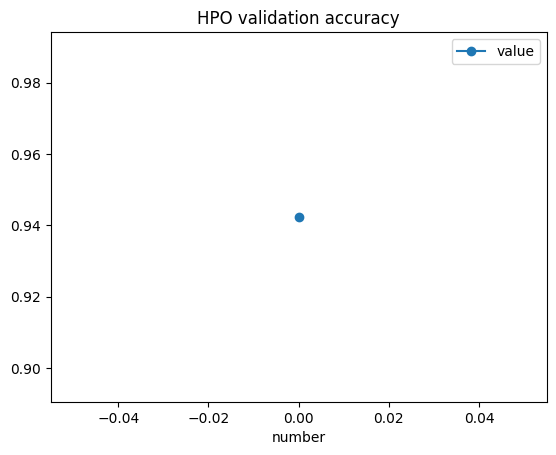

In [18]:
HPO_PROFILE = {
    "model_name": MODEL_NAME,
    "tokenizer_use_fast": TOKENIZER_USE_FAST,
    "max_length": MAX_LENGTH,
    "truncation_strategy": selected_truncation_strategy,
    "train_examples": HPO_TRAIN_EXAMPLES,
    "trials": HPO_TRIALS,
    "epochs": 3,
    "development_random_state": DEVELOPMENT_RANDOM_STATE,
    "dataset_fingerprint": DATASET_FINGERPRINT,
}
HPO_PROFILE_FINGERPRINT = object_fingerprint(HPO_PROFILE)[:12]
HPO_STUDY_PATH = HPO_ROOT / f"model_hpo_{HPO_PROFILE_FINGERPRINT}.sqlite3"
HPO_STUDY_NAME = f"imdb_model_hpo_{HPO_PROFILE_FINGERPRINT}"
hpo_frame = stratified_subset(
    model_train_df, HPO_TRAIN_EXAMPLES, DEVELOPMENT_RANDOM_STATE
)
hpo_train_dataset = tokenize_view(
    make_base_dataset(hpo_frame, True), selected_truncation_strategy
)
hpo_validation_dataset = tokenized_views[selected_truncation_strategy][
    "validation"
]
assert len(hpo_validation_dataset) == len(model_validation_df)


def objective(trial: optuna.Trial) -> float:
    configuration = TrainConfig(
        learning_rate=trial.suggest_float(
            "learning_rate", 1.2e-5, 3e-5, log=True
        ),
        weight_decay=trial.suggest_categorical(
            "weight_decay", [0.01, 0.03, 0.05]
        ),
        warmup_ratio=trial.suggest_categorical(
            "warmup_ratio", [0.05, 0.1]
        ),
        num_train_epochs=trial.suggest_categorical(
            "num_train_epochs", [3]
        ),
        effective_batch_size=trial.suggest_categorical(
            "effective_batch_size", [32]
        ),
        lr_scheduler_type=trial.suggest_categorical(
            "lr_scheduler_type", ["cosine"]
        ),
        classifier_dropout=trial.suggest_categorical(
            "classifier_dropout", [0.1, 0.2]
        ),
    )
    result = train_stage(
        f"hpo_trial_{trial.number:03d}",
        hpo_train_dataset,
        hpo_validation_dataset,
        configuration,
        seed=DEVELOPMENT_RANDOM_STATE,
        strategy=selected_truncation_strategy,
        root=HPO_ROOT / "trials",
        callbacks=[OptunaPruningCallback(trial)],
    )
    trial.set_user_attr("metrics", result["metrics"])
    trial.set_user_attr("stage_dir", result["stage_dir"])
    return float(result["metrics"]["accuracy"])


study = optuna.create_study(
    study_name=HPO_STUDY_NAME,
    storage=f"sqlite:///{HPO_STUDY_PATH}",
    direction="maximize",
    load_if_exists=True,
    sampler=optuna.samplers.TPESampler(seed=DEVELOPMENT_RANDOM_STATE),
    pruner=optuna.pruners.MedianPruner(
        n_startup_trials=1, n_warmup_steps=1
    ),
)
if RUN_HPO:
    completed_and_pruned = len(
        [
            trial
            for trial in study.trials
            if trial.state
            in {optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED}
        ]
    )
    remaining_trials = max(0, HPO_TRIALS - completed_and_pruned)
    if remaining_trials:
        study.optimize(objective, n_trials=remaining_trials, gc_after_trial=True)
    else:
        print("Reused completed Optuna study:", HPO_STUDY_PATH)

hpo_records = []
for trial in study.trials:
    record = {
        "number": trial.number,
        "state": trial.state.name,
        "value": trial.value,
        **trial.params,
        **{
            f"metric_{key}": value
            for key, value in trial.user_attrs.get("metrics", {}).items()
            if isinstance(value, (int, float))
        },
    }
    hpo_records.append(record)
hpo_results_df = pd.DataFrame(hpo_records)
hpo_results_df.to_csv(HPO_ROOT / "all_trial_results.csv", index=False)
display(hpo_results_df)
if not hpo_results_df.empty:
    completed = hpo_results_df[hpo_results_df["state"] == "COMPLETE"]
    if not completed.empty:
        completed.plot(
            x="number", y="value", marker="o", title="HPO validation accuracy"
        )
        plt.savefig(PLOT_ROOT / "hpo_validation_accuracy.png", dpi=150)
        plt.show()


## 19. Focused configuration confirmation

Selects the training configuration used by the final training stage.


In [19]:
def config_from_params(params: dict[str, Any]) -> TrainConfig:
    return TrainConfig(
        learning_rate=float(params["learning_rate"]),
        num_train_epochs=int(params["num_train_epochs"]),
        effective_batch_size=int(params["effective_batch_size"]),
        weight_decay=float(params["weight_decay"]),
        warmup_ratio=float(params["warmup_ratio"]),
        lr_scheduler_type=str(params["lr_scheduler_type"]),
        classifier_dropout=float(params["classifier_dropout"]),
    )


complete_trials = [
    trial
    for trial in study.trials
    if trial.state == optuna.trial.TrialState.COMPLETE
]
if complete_trials:
    ranked_trials = sorted(
        complete_trials, key=lambda trial: float(trial.value), reverse=True
    )[:FOCUSED_TOP_K]
    focused_configs = [
        (f"hpo_rank_{rank + 1}", config_from_params(trial.params))
        for rank, trial in enumerate(ranked_trials)
    ]
else:
    focused_configs = [("baseline_fallback", BASELINE_CONFIG)]

focused_results: dict[str, Any] = {}
if RUN_FOCUSED_CONFIRMATION:
    for config_name, configuration in focused_configs:
        runs = []
        for seed in CONFIRMATION_SEEDS:
            runs.append(
                train_stage(
                    f"focused_{config_name}_seed_{seed}",
                    tokenized_views[selected_truncation_strategy]["train"],
                    tokenized_views[selected_truncation_strategy][
                        "validation"
                    ],
                    configuration,
                    seed=seed,
                    strategy=selected_truncation_strategy,
                )
            )
        focused_results[config_name] = {
            "config": asdict(configuration),
            "runs": runs,
            "mean_accuracy": float(
                np.mean([run["metrics"]["accuracy"] for run in runs])
            ),
            "mean_f1": float(
                np.mean([run["metrics"]["f1"] for run in runs])
            ),
            "mean_log_loss": float(
                np.mean([run["metrics"]["log_loss"] for run in runs])
            ),
        }
    selected_config_name = max(
        focused_results,
        key=lambda name: (
            focused_results[name]["mean_accuracy"],
            focused_results[name]["mean_f1"],
            -focused_results[name]["mean_log_loss"],
        ),
    )
    selected_train_config = TrainConfig(
        **focused_results[selected_config_name]["config"]
    )
    atomic_write_json(
        PERSIST_ROOT / "focused_confirmation.json",
        {
            "selected": selected_config_name,
            "results": focused_results,
            "selection_data": "validation only",
        },
    )
else:
    if complete_trials:
        best_trial = max(
            complete_trials,
            key=lambda trial: float(trial.value),
        )
        selected_config_name = f"hpo_trial_{best_trial.number:03d}"
        selected_train_config = config_from_params(best_trial.params)
    else:
        selected_config_name = "baseline_fallback"
        selected_train_config = BASELINE_CONFIG

    atomic_write_json(
        PERSIST_ROOT / "focused_confirmation_selected.json",
        {
            "selected": selected_config_name,
            "config": asdict(selected_train_config),
            "selection_data": "best HPO validation result",
        },
    )

print("Selected configuration:", selected_config_name, selected_train_config)


Selected configuration: hpo_trial_000 TrainConfig(learning_rate=1.6913198431430903e-05, num_train_epochs=3, effective_batch_size=32, weight_decay=0.01, warmup_ratio=0.05, lr_scheduler_type='cosine', classifier_dropout=0.2, max_grad_norm=1.0)


## 20. LLRD decision

Sets whether layer-wise learning-rate decay is used during final training.


In [20]:
selected_use_llrd = bool(USE_LLRD)
print("Selected LLRD:", selected_use_llrd)


Selected LLRD: False


## 21. Final single-seed training

Trains the selected model with the chosen configuration and saves its final checkpoint and validation predictions.


In [21]:
def predict_checkpoint(
    model_dir: str | Path,
    dataset: Dataset,
) -> np.ndarray:
    model = AutoModelForSequenceClassification.from_pretrained(
        model_dir,
        token=False,
    ).to("cuda")
    model.eval()
    arguments = TrainingArguments(
        output_dir=str(SMOKE_ROOT / "inference_tmp"),
        per_device_eval_batch_size=8,
        fp16=True,
        bf16=False,
        report_to="none",
        dataloader_num_workers=2,
    )
    prediction_trainer = Trainer(
        model=model,
        args=arguments,
        data_collator=data_collator,
        processing_class=tokenizer,
    )
    prediction = prediction_trainer.predict(dataset)
    probability = logits_to_positive_probability(prediction.predictions)
    del prediction_trainer, model
    gc.collect()
    torch.cuda.empty_cache()
    return probability


final_seed_results: list[dict[str, Any]] = []
if RUN_FINAL_MULTI_SEED:
    for seed in FINAL_SEEDS:
        result = train_stage(
            f"final_seed_{seed}",
            tokenized_views[selected_truncation_strategy]["train"],
            tokenized_views[selected_truncation_strategy]["validation"],
            selected_train_config,
            seed=seed,
            strategy=selected_truncation_strategy,
            use_llrd=selected_use_llrd,
            root=FINAL_ROOT / "seed_models",
            retain_model=True,
        )
        alternate_strategy = (
            "head_tail"
            if selected_truncation_strategy == "head"
            else "head"
        )
        if RUN_TTA_VALIDATION:
            alternate_probability = predict_checkpoint(
                result["best_model_dir"],
                tokenized_views[alternate_strategy]["validation"],
            )
            alternate_path = (
                Path(result["best_model_dir"]).parent
                / "validation_alternate_view.npz"
            )
            np.savez_compressed(
                alternate_path,
                positive_probability=alternate_probability,
                labels=model_validation_df["sentiment"].to_numpy(np.int64),
                strategy=alternate_strategy,
            )
            result = {
                **result,
                "alternate_validation_predictions": str(alternate_path),
                "alternate_strategy": alternate_strategy,
            }
        final_seed_results.append(result)
    atomic_write_json(
        FINAL_ROOT / "final_seed_results.json", final_seed_results
    )
else:
    saved_final_results = FINAL_ROOT / "final_seed_results.json"
    if not saved_final_results.is_file():
        raise FileNotFoundError(
            "RUN_FINAL_MULTI_SEED=False requires an existing final_seed_results.json."
        )
    final_seed_results = json.loads(
        saved_final_results.read_text(encoding="utf-8")
    )

assert [item["metadata"]["seed"] for item in final_seed_results] == FINAL_SEEDS
print(
    pd.DataFrame(
        [
            {
                "seed": item["metadata"]["seed"],
                **{
                    key: item["metrics"][key]
                    for key in ["accuracy", "f1", "log_loss", "roc_auc"]
                },
                "best_epoch": item["best_epoch"],
            }
            for item in final_seed_results
        ]
    )
)


Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/deberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Macro F1,Roc Auc,Log Loss,Runtime,Samples Per Second,Steps Per Second
1,0.136200,0.162084,0.944780,0.975150,0.913323,0.943224,0.944739,0.989785,0.162084,22.919200,108.250000,13.569000
2,0.077700,0.162173,0.954454,0.948535,0.961477,0.954962,0.954448,0.990062,0.162174,22.783000,108.897000,13.651000
3,0.057200,0.182867,0.953648,0.948454,0.959872,0.954128,0.953643,0.990236,0.182867,22.444300,110.540000,13.857000


   seed  accuracy        f1  log_loss   roc_auc  best_epoch
0    42  0.954454  0.954962  0.162177  0.990062         2.0


## 22. Validation ensemble selection

Builds the validation probability set used by the final prediction configuration.


In [22]:
def soft_vote(
    probability_matrix: np.ndarray,
    weights: Sequence[float],
) -> np.ndarray:
    matrix = np.asarray(probability_matrix, dtype=np.float64)
    weight_array = np.asarray(weights, dtype=np.float64)
    if matrix.ndim != 2 or matrix.shape[0] != len(weight_array):
        raise ValueError("Expected [models, examples] and one weight per model.")
    if not np.isfinite(matrix).all() or not np.isfinite(weight_array).all():
        raise ValueError("Probabilities and weights must be finite.")
    if np.any((matrix < 0) | (matrix > 1)):
        raise ValueError("Probabilities must be in [0, 1].")
    if np.any(weight_array < 0) or not np.isclose(weight_array.sum(), 1.0):
        raise ValueError("Weights must be nonnegative and sum to 1.")
    return np.average(matrix, axis=0, weights=weight_array)


validation_probability_rows = []
alternate_probability_rows = []
validation_labels = None
for result in final_seed_results:
    with np.load(result["validation_predictions"], allow_pickle=False) as prediction:
        validation_probability_rows.append(
            prediction["positive_probability"].copy()
        )
        labels = prediction["labels"].astype(np.int64, copy=True)
    if validation_labels is None:
        validation_labels = labels
    else:
        assert np.array_equal(validation_labels, labels)
    if RUN_TTA_VALIDATION and "alternate_validation_predictions" in result:
        with np.load(
            result["alternate_validation_predictions"], allow_pickle=False
        ) as alternate_prediction:
            alternate_probability_rows.append(
                alternate_prediction["positive_probability"].copy()
            )
probability_matrix = np.vstack(validation_probability_rows)
assert validation_labels is not None


def candidate_rank(metrics: dict[str, Any]) -> tuple[float, float, float]:
    return (
        metrics["accuracy"],
        metrics["f1"],
        -metrics["log_loss"],
    )


ensemble_candidates: list[dict[str, Any]] = []
for index, result in enumerate(final_seed_results):
    metrics = metrics_from_probabilities(
        validation_labels, probability_matrix[index]
    )
    ensemble_candidates.append(
        {
            "name": f"single_seed_{result['metadata']['seed']}",
            "weights": [
                1.0 if member == index else 0.0
                for member in range(len(final_seed_results))
            ],
            "use_tta": False,
            "metrics": metrics,
        }
    )

equal_weights = np.full(
    len(final_seed_results), 1 / len(final_seed_results)
)
if len(final_seed_results) > 1:
    equal_probability = soft_vote(probability_matrix, equal_weights)
    ensemble_candidates.append(
        {
            "name": "equal_soft_vote",
            "weights": equal_weights.tolist(),
            "use_tta": False,
            "metrics": metrics_from_probabilities(
                validation_labels, equal_probability
            ),
        }
    )

if RUN_ENSEMBLE_SELECTION and len(final_seed_results) > 1:
    grid = np.arange(0.0, 1.01, 0.1)
    valid_weights = [
        values
        for values in itertools.product(grid, repeat=len(final_seed_results))
        if np.isclose(sum(values), 1.0)
    ]
    best_weighted = max(
        valid_weights,
        key=lambda values: candidate_rank(
            metrics_from_probabilities(
                validation_labels, soft_vote(probability_matrix, values)
            )
        ),
    )
    ensemble_candidates.append(
        {
            "name": "restricted_weighted_soft_vote",
            "weights": list(map(float, best_weighted)),
            "use_tta": False,
            "metrics": metrics_from_probabilities(
                validation_labels,
                soft_vote(probability_matrix, best_weighted),
            ),
        }
    )

if RUN_TTA_VALIDATION and len(alternate_probability_rows) == len(
    final_seed_results
):
    alternate_matrix = np.vstack(alternate_probability_rows)
    tta_matrix = (probability_matrix + alternate_matrix) / 2
    tta_probability = soft_vote(tta_matrix, equal_weights)
    ensemble_candidates.append(
        {
            "name": "equal_soft_vote_with_head_head_tail_tta",
            "weights": equal_weights.tolist(),
            "use_tta": True,
            "metrics": metrics_from_probabilities(
                validation_labels, tta_probability
            ),
        }
    )

selected_ensemble = max(
    ensemble_candidates, key=lambda item: candidate_rank(item["metrics"])
)
best_single_candidate = max(
    [
        item
        for item in ensemble_candidates
        if item["name"].startswith("single_seed_")
    ],
    key=lambda item: candidate_rank(item["metrics"]),
)
best_single_checkpoint_index = int(
    np.argmax(best_single_candidate["weights"])
)
selected_probability_matrix = (
    (probability_matrix + np.vstack(alternate_probability_rows)) / 2
    if selected_ensemble["use_tta"]
    else probability_matrix
)
selected_validation_probability = soft_vote(
    selected_probability_matrix, selected_ensemble["weights"]
)
atomic_write_json(
    FINAL_ROOT / "ensemble_configuration.json",
    {
        "selected": selected_ensemble,
        "all_candidates": ensemble_candidates,
        "selection_data": "validation only",
    },
)
display(
    pd.DataFrame(
        [
            {
                "name": item["name"],
                "weights": item["weights"],
                "use_tta": item["use_tta"],
                "accuracy": item["metrics"]["accuracy"],
                "f1": item["metrics"]["f1"],
                "log_loss": item["metrics"]["log_loss"],
            }
            for item in ensemble_candidates
        ]
    )
)


,name,weights,use_tta,accuracy,f1,log_loss
0,single_seed_42,[1.0],False,0.954454,0.954962,0.162177


## 23. Validation threshold selection

Selects the classification threshold from validation predictions.


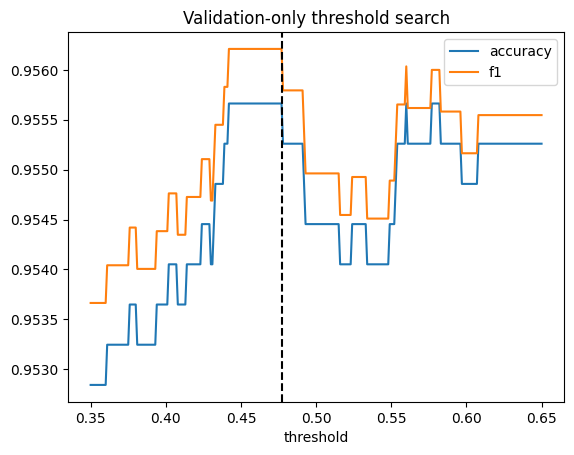

Validation-selected threshold: {'threshold': 0.477, 'accuracy': 0.9556630390971382, 'f1': 0.9562101910828026}


In [23]:
def search_threshold(
    labels: np.ndarray,
    probability: np.ndarray,
) -> tuple[dict[str, Any], pd.DataFrame]:
    records = []
    for threshold in np.round(np.arange(0.35, 0.6501, 0.001), 3):
        metrics = metrics_from_probabilities(labels, probability, threshold)
        records.append(
            {
                "threshold": float(threshold),
                "accuracy": metrics["accuracy"],
                "f1": metrics["f1"],
            }
        )
    table = pd.DataFrame(records)
    best = max(
        records,
        key=lambda row: (
            row["accuracy"],
            row["f1"],
            -abs(row["threshold"] - 0.5),
            -row["threshold"],
        ),
    )
    return best, table


if RUN_THRESHOLD_SEARCH:
    selected_threshold, threshold_table = search_threshold(
        validation_labels, selected_validation_probability
    )
    threshold_table.to_csv(
        FINAL_ROOT / "threshold_search_results.csv", index=False
    )
    atomic_write_json(
        FINAL_ROOT / "threshold_selection.json",
        {
            "selected": selected_threshold,
            "baseline_0_5": metrics_from_probabilities(
                validation_labels, selected_validation_probability, 0.5
            ),
            "selection_data": "validation only",
        },
    )
    threshold_table.plot(
        x="threshold",
        y=["accuracy", "f1"],
        title="Validation-only threshold search",
    )
    plt.axvline(selected_threshold["threshold"], color="black", linestyle="--")
    plt.savefig(PLOT_ROOT / "validation_threshold_search.png", dpi=150)
    plt.show()
else:
    selected_threshold = json.loads(
        (FINAL_ROOT / "threshold_selection.json").read_text(encoding="utf-8")
    )["selected"]

assert 0.35 <= selected_threshold["threshold"] <= 0.65
print("Validation-selected threshold:", selected_threshold)


## 24. Frozen final configuration

Saves the selected model, checkpoint hashes, threshold, and training settings in an immutable configuration.


In [24]:
checkpoint_records = [
    {
        "seed": result["metadata"]["seed"],
        "model_dir": result["best_model_dir"],
        "config_sha256": file_sha256(
            Path(result["best_model_dir"]) / "config.json"
        ),
        "model_file_sha256": file_sha256(
            next(Path(result["best_model_dir"]).glob("model*.safetensors"))
        ),
    }
    for result in final_seed_results
]
frozen_payload = {
    "schema_version": 1,
    "model_name": MODEL_NAME,
    "max_length": MAX_LENGTH,
    "preprocessing": "minimal_normalize_v1",
    "truncation_strategy": selected_truncation_strategy,
    "train_config": asdict(selected_train_config),
    "use_llrd": selected_use_llrd,
    "llrd_decay": 0.9 if selected_use_llrd else None,
    "seeds": FINAL_SEEDS,
    "checkpoints": checkpoint_records,
    "ensemble": {
        "name": selected_ensemble["name"],
        "weights": selected_ensemble["weights"],
    },
    "best_single_checkpoint_index": best_single_checkpoint_index,
    "threshold": selected_threshold["threshold"],
    "use_tta": selected_ensemble["use_tta"],
    "tta_views": ["head", "head_tail"]
    if selected_ensemble["use_tta"]
    else [selected_truncation_strategy],
    "dataset_fingerprint": DATASET_FINGERPRINT,
    "locked_test_labels_sha256": LOCKED_TEST_LABELS_SHA256,
    "package_versions": PACKAGE_VERSIONS,
    "selection_data": "validation only",
}
FROZEN_CONFIG_FINGERPRINT = object_fingerprint(frozen_payload)
FROZEN_CONFIG_PATH = (
    FINAL_ROOT
    / "frozen_configs"
    / f"final_{FROZEN_CONFIG_FINGERPRINT}.json"
)
if FROZEN_CONFIG_PATH.is_file():
    assert json.loads(
        FROZEN_CONFIG_PATH.read_text(encoding="utf-8")
    ) == frozen_payload
    print("Reused identical frozen configuration:", FROZEN_CONFIG_PATH)
else:
    atomic_write_json(FROZEN_CONFIG_PATH, frozen_payload)
    print("Wrote immutable frozen configuration:", FROZEN_CONFIG_PATH)
print("Frozen configuration fingerprint:", FROZEN_CONFIG_FINGERPRINT)


Wrote immutable frozen configuration: /content/drive/MyDrive/sentiment_analysis_transformer/final/frozen_configs/final_db302e66a1def80c7493849f7bc10abe64db0a2073d8dc9fa37efc6f4ae0cabf.json
Frozen configuration fingerprint: db302e66a1def80c7493849f7bc10abe64db0a2073d8dc9fa37efc6f4ae0cabf


## 25. Frozen-configuration verification

Verifies the frozen configuration and retained model files before final evaluation or inference.


In [25]:
def verify_frozen_config(
    path: str | Path,
    expected_fingerprint: str,
) -> dict[str, Any]:
    config_path = Path(path)
    if not config_path.is_file():
        raise FileNotFoundError(f"Frozen configuration not found: {config_path}")

    payload = json.loads(config_path.read_text(encoding="utf-8"))
    actual_fingerprint = object_fingerprint(payload)
    if actual_fingerprint != expected_fingerprint:
        raise RuntimeError(
            "Frozen configuration fingerprint mismatch: "
            f"{actual_fingerprint} != {expected_fingerprint}"
        )

    if payload["dataset_fingerprint"] != DATASET_FINGERPRINT:
        raise RuntimeError("Dataset fingerprint does not match the frozen configuration.")
    if payload["locked_test_labels_sha256"] != LOCKED_TEST_LABELS_SHA256:
        raise RuntimeError("Locked test-label hash does not match the frozen configuration.")

    for checkpoint in payload["checkpoints"]:
        model_dir = Path(checkpoint["model_dir"])
        config_file = model_dir / "config.json"
        model_files = sorted(model_dir.glob("model*.safetensors"))
        if not config_file.is_file() or not model_files:
            raise FileNotFoundError(
                f"Frozen checkpoint files are missing in: {model_dir}"
            )
        if file_sha256(config_file) != checkpoint["config_sha256"]:
            raise RuntimeError(f"config.json hash mismatch in: {model_dir}")
        if file_sha256(model_files[0]) != checkpoint["model_file_sha256"]:
            raise RuntimeError(f"Model hash mismatch in: {model_dir}")

    return payload


verified_frozen_config = verify_frozen_config(
    FROZEN_CONFIG_PATH,
    FROZEN_CONFIG_FINGERPRINT,
)
print("Frozen configuration verified.")


Frozen configuration verified.


## 26. Official test evaluation

Evaluates the frozen selected model on the official test set and saves the resulting predictions and metrics.


In [26]:
if not ALLOW_FINAL_TEST_EVALUATION:
    raise RuntimeError(
        "Run All requires ALLOW_FINAL_TEST_EVALUATION=True. "
        "Development choices have already been frozen before this cell."
    )

final_test_result = None

frozen = verify_frozen_config(
    FROZEN_CONFIG_PATH,
    FROZEN_CONFIG_FINGERPRINT,
)

official_result_dir = (
    FINAL_ROOT / "official_test" / FROZEN_CONFIG_FINGERPRINT
)
official_result_dir.mkdir(parents=True, exist_ok=True)
result_json_path = official_result_dir / "metrics.json"
prediction_path = official_result_dir / "predictions.npz"

if result_json_path.is_file() and prediction_path.is_file():
    final_test_result = json.loads(
        result_json_path.read_text(encoding="utf-8")
    )
    if (
        final_test_result.get("frozen_config_fingerprint")
        != FROZEN_CONFIG_FINGERPRINT
    ):
        raise RuntimeError("Cached official test result has the wrong fingerprint.")

    locked_labels = np.load(LOCKED_TEST_LABELS_PATH).astype(np.int64)
    if file_sha256(LOCKED_TEST_LABELS_PATH) != LOCKED_TEST_LABELS_SHA256:
        raise RuntimeError("Locked official test labels changed on disk.")
    with np.load(prediction_path, allow_pickle=False) as cached_predictions:
        cached_probability = cached_predictions["positive_probability"].astype(
            np.float64, copy=True
        )
        cached_labels = cached_predictions["labels"].astype(np.int64, copy=True)
        cached_threshold = float(cached_predictions["threshold"])

    expected_test_count = len(
        tokenized_views[frozen["truncation_strategy"]]["test_inputs"]
    )
    if len(cached_probability) != expected_test_count:
        raise RuntimeError("Cached official test predictions have the wrong length.")
    if not np.array_equal(cached_labels, locked_labels):
        raise RuntimeError("Cached official test labels do not match the locked labels.")
    if not np.isclose(cached_threshold, float(frozen["threshold"])):
        raise RuntimeError("Cached official test threshold does not match the frozen config.")
    if not np.isfinite(cached_probability).all() or np.any(
        (cached_probability < 0) | (cached_probability > 1)
    ):
        raise RuntimeError("Cached official test probabilities are invalid.")

    cached_prediction_sha256 = file_sha256(prediction_path)
    saved_prediction_sha256 = final_test_result.get("prediction_sha256")
    if (
        saved_prediction_sha256 is not None
        and saved_prediction_sha256 != cached_prediction_sha256
    ):
        raise RuntimeError("Cached official test prediction-file hash mismatch.")

    final_test_result["metrics"] = metrics_from_probabilities(
        locked_labels, cached_probability, cached_threshold
    )
    final_test_result["prediction_sha256"] = cached_prediction_sha256
    final_test_result["examples"] = int(len(locked_labels))
    final_test_result["threshold"] = cached_threshold
    atomic_write_json(result_json_path, final_test_result)
    del locked_labels, cached_labels, cached_probability
    print("Reused verified official test result:", result_json_path)
else:
    test_labels = np.load(LOCKED_TEST_LABELS_PATH).astype(np.int64)
    if file_sha256(LOCKED_TEST_LABELS_PATH) != LOCKED_TEST_LABELS_SHA256:
        raise RuntimeError("Locked official test labels changed on disk.")

    test_probability_rows = []
    for checkpoint in frozen["checkpoints"]:
        probability = predict_checkpoint(
            checkpoint["model_dir"],
            tokenized_views[frozen["truncation_strategy"]]["test_inputs"],
        )
        if frozen["use_tta"]:
            alternate_strategy = (
                "head_tail"
                if frozen["truncation_strategy"] == "head"
                else "head"
            )
            alternate_probability = predict_checkpoint(
                checkpoint["model_dir"],
                tokenized_views[alternate_strategy]["test_inputs"],
            )
            probability = (probability + alternate_probability) / 2
        test_probability_rows.append(probability)

    test_probability_matrix = np.vstack(test_probability_rows)
    test_positive_probability = soft_vote(
        test_probability_matrix,
        frozen["ensemble"]["weights"],
    )
    test_metrics = metrics_from_probabilities(
        test_labels,
        test_positive_probability,
        frozen["threshold"],
    )

    np.savez_compressed(
        prediction_path,
        positive_probability=test_positive_probability,
        labels=test_labels,
        threshold=float(frozen["threshold"]),
    )

    final_test_result = {
        "frozen_config_fingerprint": FROZEN_CONFIG_FINGERPRINT,
        "result_dir": str(official_result_dir),
        "prediction_file": str(prediction_path),
        "prediction_sha256": file_sha256(prediction_path),
        "metrics": test_metrics,
        "examples": int(len(test_labels)),
        "threshold": float(frozen["threshold"]),
    }
    atomic_write_json(result_json_path, final_test_result)
    del test_labels, test_probability_matrix, test_probability_rows
    gc.collect()
    torch.cuda.empty_cache()

print(json.dumps(final_test_result, indent=2))

if final_test_result is None:
    raise RuntimeError("Official test evaluation did not produce a result.")

required_metric_keys = {"accuracy", "f1", "log_loss", "roc_auc"}
if not required_metric_keys.issubset(final_test_result["metrics"]):
    raise RuntimeError(
        "Official test result is incomplete: missing required metrics."
    )

display(pd.DataFrame([final_test_result["metrics"]]))
print("Official test artifacts:", final_test_result["result_dir"])


{
  "frozen_config_fingerprint": "db302e66a1def80c7493849f7bc10abe64db0a2073d8dc9fa37efc6f4ae0cabf",
  "result_dir": "/content/drive/MyDrive/sentiment_analysis_transformer/final/official_test/db302e66a1def80c7493849f7bc10abe64db0a2073d8dc9fa37efc6f4ae0cabf",
  "prediction_file": "/content/drive/MyDrive/sentiment_analysis_transformer/final/official_test/db302e66a1def80c7493849f7bc10abe64db0a2073d8dc9fa37efc6f4ae0cabf/predictions.npz",
  "prediction_sha256": "a5a39f4b86845ae297089521b974611ddbb5a3ae33299e938f9a1ccdafdbfe9d",
  "metrics": {
    "accuracy": 0.96088,
    "precision": 0.9507119386637459,
    "recall": 0.97216,
    "f1": 0.9613163515544656,
    "macro_f1": 0.9608750218003739,
    "roc_auc": 0.992435184,
    "log_loss": 0.1306040386149452,
    "confusion_matrix": [
      [
        11870,
        630
      ],
      [
        348,
        12152
      ]
    ],
    "classification_report": "              precision    recall  f1-score   support\n\n    negative   0.971517  0.949600 

,accuracy,precision,recall,f1,macro_f1,roc_auc,log_loss,confusion_matrix,classification_report,threshold
0,0.96088,0.950712,0.97216,0.961316,0.960875,0.992435,0.130604,"[[11870, 630], [348, 12152]]",precision recall f1-score ...,0.477


Official test artifacts: /content/drive/MyDrive/sentiment_analysis_transformer/final/official_test/db302e66a1def80c7493849f7bc10abe64db0a2073d8dc9fa37efc6f4ae0cabf


## 27. Inference function

Defines the reusable prediction function for new review text using the frozen selected model.


In [27]:
def encode_inference_texts(
    texts: Sequence[str],
    strategy: str,
    max_length: int,
) -> list[dict[str, list[int]]]:
    normalized = [minimal_normalize(text) for text in texts]
    if strategy == "head":
        batch = tokenizer(
            normalized,
            truncation=True,
            max_length=max_length,
            padding=False,
        )
        return [
            {key: batch[key][index] for key in ["input_ids", "attention_mask"]}
            for index in range(len(normalized))
        ]
    return [
        head_tail_encode_text(text, max_length=max_length)
        for text in normalized
    ]


def checkpoint_probabilities_for_texts(
    model_dir: str | Path,
    texts: Sequence[str],
    strategy: str,
    max_length: int,
) -> np.ndarray:
    model = AutoModelForSequenceClassification.from_pretrained(
        model_dir,
        token=False,
    ).to("cuda")
    model.eval()
    records = encode_inference_texts(texts, strategy, max_length)
    values: list[np.ndarray] = []
    with torch.inference_mode():
        for start in range(0, len(records), 8):
            batch = data_collator(records[start : start + 8])
            batch = {key: value.to("cuda") for key, value in batch.items()}
            logits = model(**batch).logits.float().cpu().numpy()
            values.append(logits_to_positive_probability(logits))
    del model
    gc.collect()
    torch.cuda.empty_cache()
    return np.concatenate(values)


def predict_sentiment(
    text: str | Sequence[str],
    use_ensemble: bool = True,
) -> dict[str, Any] | list[dict[str, Any]]:
    single = isinstance(text, str)
    texts = [text] if single else list(text)
    if not texts or not all(isinstance(item, str) and item.strip() for item in texts):
        raise ValueError("Provide a non-empty string or sequence of strings.")
    frozen = verify_frozen_config(
        FROZEN_CONFIG_PATH, FROZEN_CONFIG_FINGERPRINT
    )
    checkpoint_subset = (
        frozen["checkpoints"]
        if use_ensemble
        else [
            frozen["checkpoints"][
                frozen["best_single_checkpoint_index"]
            ]
        ]
    )
    weights = (
        frozen["ensemble"]["weights"]
        if use_ensemble
        else [1.0]
    )
    probability_rows = []
    for checkpoint in checkpoint_subset:
        probability = checkpoint_probabilities_for_texts(
            checkpoint["model_dir"],
            texts,
            frozen["truncation_strategy"],
            frozen["max_length"],
        )
        if frozen["use_tta"]:
            alternate = (
                "head_tail"
                if frozen["truncation_strategy"] == "head"
                else "head"
            )
            probability = (
                probability
                + checkpoint_probabilities_for_texts(
                    checkpoint["model_dir"],
                    texts,
                    alternate,
                    frozen["max_length"],
                )
            ) / 2
        probability_rows.append(probability)
    selected_weights = (
        weights
        if use_ensemble
        else [1.0]
    )
    positive = soft_vote(np.vstack(probability_rows), selected_weights)
    results = []
    for probability in positive:
        label_id = int(probability >= frozen["threshold"])
        results.append(
            {
                "label": "positive" if label_id == 1 else "negative",
                "label_id": label_id,
                "positive_probability": float(probability),
                "negative_probability": float(1 - probability),
                "confidence": float(max(probability, 1 - probability)),
                "threshold": float(frozen["threshold"]),
                "model_type": (
                    f"{frozen['model_name']}-ensemble"
                    if use_ensemble
                    else f"{frozen['model_name']}-single"
                ),
            }
        )
    return results[0] if single else results


## 28. Example predictions

Runs the inference function on example reviews and displays their predictions.


In [28]:
example_reviews = [
    "This film was thoughtful, beautifully acted, and genuinely moving.",
    "A tedious mess with terrible dialogue; I regretted watching it.",
]
example_predictions = predict_sentiment(example_reviews, use_ensemble=True)
display(pd.DataFrame(example_predictions))
assert example_predictions[0]["label_id"] in {0, 1}
assert example_predictions[1]["label_id"] in {0, 1}


,label,label_id,positive_probability,negative_probability,confidence,threshold,model_type
0,positive,1,0.995433,0.004567,0.995433,0.477,microsoft/deberta-v3-base-ensemble
1,negative,0,0.001390,0.998610,0.998610,0.477,microsoft/deberta-v3-base-ensemble


## 29. Artifact summary

Displays the main saved artifact paths produced by the completed run.


In [29]:
artifact_summary = {
    "persistent_root": str(PERSIST_ROOT),
    "dataset_manifest": str(PERSIST_ROOT / "dataset_manifest.json"),
    "token_length_statistics": str(
        PERSIST_ROOT / "token_length_statistics.json"
    ),
    "model_screening_results": str(MODEL_SCREENING_PATH),
    "hpo_database": str(HPO_STUDY_PATH),
    "hpo_results": str(HPO_ROOT / "all_trial_results.csv"),
    "final_seed_results": str(FINAL_ROOT / "final_seed_results.json"),
    "ensemble_configuration": str(
        FINAL_ROOT / "ensemble_configuration.json"
    ),
    "threshold_selection": str(FINAL_ROOT / "threshold_selection.json"),
    "frozen_configuration": str(FROZEN_CONFIG_PATH),
    "final_test_gate_open": ALLOW_FINAL_TEST_EVALUATION,
    "final_test_result": final_test_result["result_dir"],
    "smoke_artifacts": str(SMOKE_ROOT),
}
print(json.dumps(artifact_summary, indent=2))


{
  "persistent_root": "/content/drive/MyDrive/sentiment_analysis_transformer",
  "dataset_manifest": "/content/drive/MyDrive/sentiment_analysis_transformer/dataset_manifest.json",
  "token_length_statistics": "/content/drive/MyDrive/sentiment_analysis_transformer/token_length_statistics.json",
  "model_screening_results": "/content/drive/MyDrive/sentiment_analysis_transformer/model_screening_results_32931dd609bc.json",
  "hpo_database": "/content/drive/MyDrive/sentiment_analysis_transformer/hpo/model_hpo_ea0635483548.sqlite3",
  "hpo_results": "/content/drive/MyDrive/sentiment_analysis_transformer/hpo/all_trial_results.csv",
  "final_seed_results": "/content/drive/MyDrive/sentiment_analysis_transformer/final/final_seed_results.json",
  "ensemble_configuration": "/content/drive/MyDrive/sentiment_analysis_transformer/final/ensemble_configuration.json",
  "threshold_selection": "/content/drive/MyDrive/sentiment_analysis_transformer/final/threshold_selection.json",
  "frozen_configuration

## 30. Final status

Checks that final evaluation completed and prints the final selected model and configuration status.


In [30]:
assert final_test_result is not None, "Final test result is required."

final_status = {
    "model": MODEL_NAME,
    "max_length": MAX_LENGTH,
    "selected_truncation_strategy": selected_truncation_strategy,
    "selected_train_config": asdict(selected_train_config),
    "selected_use_llrd": selected_use_llrd,
    "selected_ensemble": selected_ensemble["name"],
    "selected_threshold": selected_threshold["threshold"],
    "final_seeds": FINAL_SEEDS,
    "test_status": "evaluated with frozen configuration",
    "frozen_config_fingerprint": FROZEN_CONFIG_FINGERPRINT,
}
print(json.dumps(final_status, indent=2))


{
  "model": "microsoft/deberta-v3-base",
  "max_length": 384,
  "selected_truncation_strategy": "head_tail",
  "selected_train_config": {
    "learning_rate": 1.6913198431430903e-05,
    "num_train_epochs": 3,
    "effective_batch_size": 32,
    "weight_decay": 0.01,
    "warmup_ratio": 0.05,
    "lr_scheduler_type": "cosine",
    "classifier_dropout": 0.2,
    "max_grad_norm": 1.0
  },
  "selected_use_llrd": false,
  "selected_ensemble": "single_seed_42",
  "selected_threshold": 0.477,
  "final_seeds": [
    42
  ],
  "test_status": "evaluated with frozen configuration",
  "frozen_config_fingerprint": "db302e66a1def80c7493849f7bc10abe64db0a2073d8dc9fa37efc6f4ae0cabf"
}
